# Layer 1: vendor-level baseline
Layer 1 only uses information about one vendor at a time:
- the vendor's own fields
- its own rows in the sub-tables (engagements, payments, approvals, services, institution links, addresses)
- reference tables (approval policy, employee roles, country risk)

Feature-scope check: adding a new vendor should not change an existing vendor's raw feature values. This check concerns feature construction, not fitted preprocessing or model scores. "Number of sponsors of this vendor" is Layer 1, "which vendors share a sponsor" is Layer 2.

Outline:
1. load, clean, build y and features
2. supervised: variable selection with 4 penalized models, 5 models on one 4:1 split
3. unsupervised: Isolation Forest
4. out-of-fold evaluation over 5 seeds + ablations
5. save outputs for Layer 2

y = 0 means "not in a labelled case", not "clean". If positive labels are incomplete but correct, precision against the observed labels may understate true positive retrieval. It does not establish precision for real-world compliance risk.

## Setup and loading
`DATA_DIR`: folder with the csv files. `N_SEEDS` for the 5-seed evaluation, `N_JOBS` for parallel folds.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import re
import os
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

DATA_DIR = "student_bundle"
N_SEEDS = 5
N_JOBS = 2
SNAPSHOT = pd.Timestamp("2026-06-30")
ERP_DATE = pd.Timestamp("2022-05-01")          # ERP migration (business_events)
GENERIC_EMAIL = {"gmail.com", "outlook.com", "yahoo.com", "hotmail.com", "icloud.com"}


def rd(name, dates=()):
    df = pd.read_csv(os.path.join(DATA_DIR, name))
    for c in dates:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    return df


tp = rd("third_parties.csv", ["onboarding_date", "created_date", "terminated_date"])
dd = rd("tp_due_diligence.csv", ["dd_completed", "dd_refresh_due"])
addr = rd("tp_address_history.csv", ["valid_from", "valid_to", "observed_at"])
svc = rd("tp_services.csv", ["valid_from", "valid_to"])
eng = rd("tp_engagements.csv", ["start_date", "end_date", "observed_at"])
appr = rd("tp_engagement_approvals.csv", ["approval_date", "observed_at"])
pay = rd("tp_payments_monthly.csv", ["month"])
inst_l = rd("tp_institution_links.csv", ["valid_from", "valid_to"])
inst = rd("healthcare_institutions.csv")
roles = rd("employee_roles.csv", ["valid_from", "valid_to"])
cats = rd("service_categories.csv").rename(columns={"flags": "rflags"})
policy = rd("approval_policy_matrix.csv")
crc = rd("country_risk_context.csv", ["as_of_date"])
mkts = rd("markets.csv")
fmv = rd("fmv_rate_cards.csv", ["effective_from", "effective_to"])
labels = rd("labelled_cases_TRAINING_SET.csv")
OUT = 'results'
os.makedirs(OUT, exist_ok=True)

from IPython.display import display
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
print('third_parties:', tp.shape, '| engagements:', eng.shape, '| payments:', pay.shape)

third_parties: (1002, 16) | engagements: (2638, 12) | payments: (34467, 18)


## Cleaning
- strip strings, empty string → NaN, drop exact duplicate rows
- null `valid_to` / `end_date` = still open → filled with the snapshot date (`*_f` columns)
- service categories come in two taxonomy versions; use the crosswalk to derive risk flags and category parents, taking the union of flags for v1 codes with multiple v2 mappings. Raw category codes are still used for category counts, so these counts are not fully harmonized across versions.
- the `system_default` sponsor is the ERP-migration fallback account, not a person → NaN in `sponsor_clean`
- addresses: lower-case, drop punctuation, expand abbreviations, sort tokens, merge small typos. Typos are only merged within one vendor's own addresses; merging across vendors would be Layer 2.

In [2]:
# strip strings, "" -> NaN
for df in [tp, dd, addr, svc, eng, appr, pay, inst_l, roles, cats]:
    for c in df.select_dtypes(include=["object", "string"]).columns:
        df[c] = df[c].astype("string").str.strip().replace({"": pd.NA})

# exact duplicate rows
for name, df in [("addr", addr), ("svc", svc), ("eng", eng), ("appr", appr), ("pay", pay)]:
    n0 = len(df)
    df.drop_duplicates(inplace=True)
    if n0 != len(df):
        print(f"[clean] {name}: dropped {n0 - len(df)} exact duplicate rows")

# null valid_to / end_date = still open
addr["valid_to_f"] = addr["valid_to"].fillna(SNAPSHOT)
svc["valid_to_f"] = svc["valid_to"].fillna(SNAPSHOT)
eng["end_f"] = eng["end_date"].fillna(SNAPSHOT)
inst_l["valid_to_f"] = inst_l["valid_to"].fillna(SNAPSHOT)

# taxonomy v1 -> v2: a v1 code can map to several v2 codes, take the union of flags
cats["rflags"] = cats["rflags"].fillna("")
flag_v2 = dict(zip(cats.category_code_v2, cats["rflags"]))
parent_v2 = dict(zip(cats.category_code_v2, cats.parent))
flag_v1 = cats.groupby("category_code_v1")["rflags"].apply(
    lambda s: ";".join(sorted({f for x in s for f in x.split(";") if f}))).to_dict()
parent_v1 = cats.groupby("category_code_v1")["parent"].first().to_dict()


def cat_flags(code, ver):
    return (flag_v2 if ver == "v2" else flag_v1).get(code, "")


def cat_parent(code, ver):
    p = (parent_v2 if ver == "v2" else parent_v1).get(code)
    return p if p is not None else (code.split(".")[0] if isinstance(code, str) else None)


eng["rflags"] = [cat_flags(c, v) for c, v in zip(eng.service_category, eng.taxonomy_version)]
eng["cat_parent"] = [cat_parent(c, v) for c, v in zip(eng.service_category, eng.taxonomy_version)]
svc["rflags"] = [cat_flags(c, v) for c, v in zip(svc.category_code, svc.taxonomy_version)]

# system_default sponsor = ERP fallback account
role_of = dict(zip(roles.employee_id, roles.role))
lvl_of = dict(zip(roles.employee_id, roles.approver_level))
sys_emps = set(roles.loc[roles.role == "system_default", "employee_id"])
eng["sponsor_is_system"] = eng.sponsor_employee_id.isin(sys_emps)
eng["sponsor_clean"] = eng.sponsor_employee_id.where(~eng.sponsor_is_system)  # NaN if system

# address normalisation
ABBR = {"st": "street", "str": "street", "rd": "road", "ave": "avenue", "av": "avenue",
        "blvd": "boulevard", "ste": "suite", "fl": "floor", "apt": "apartment", "dr": "drive",
        "ln": "lane", "ct": "court", "hwy": "highway", "no": "number", "bldg": "building",
        "sq": "square", "pl": "place", "ctr": "center", "centre": "center"}


def norm_addr(s):
    if pd.isna(s):
        return None
    s = str(s).lower()
    s = re.sub(r"[^\w\s]", " ", s)                  # punctuation -> space
    toks = [ABBR.get(t, t) for t in s.split()]
    return " ".join(sorted(toks))                    # sort tokens so field order doesn't matter


addr["addr_key"] = addr.raw_address.map(norm_addr) + "|" + addr.address_country.fillna("")


# merge keys in the same country that differ by one token
def merge_typos(keys):
    parent = {k: k for k in keys}

    def f(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    by_c = defaultdict(list)
    for k in keys:
        by_c[k.split("|")[1]].append(k)
    for _, ks in by_c.items():
        toks = {k: set(k.split("|")[0].split()) for k in ks}
        for a, b in combinations(ks, 2):
            ta, tb = toks[a], toks[b]
            if len(ta) >= 4 and len(ta ^ tb) <= 2 and len(ta & tb) >= len(ta) - 1:
                parent[f(a)] = f(b)
    return {k: f(k) for k in keys}


# only within one vendor's addresses
def merge_typos_within_vendor(df):
    out = df["addr_key"].copy()
    for rid, idx in df.dropna(subset=["addr_key"]).groupby("record_id").groups.items():
        keys = df.loc[idx, "addr_key"].unique()
        if len(keys) > 1:
            out.loc[idx] = df.loc[idx, "addr_key"].map(merge_typos(keys))
    return out


addr["addr_key"] = merge_typos_within_vendor(addr)

# country context (CPI is in the feature cell)
bo = crc[crc["index"] == "BO_REGISTER_ACCESS"].sort_values("as_of_date").groupby("iso2").last()
bo_map = bo["tier"].map({"high": 0, "medium": 1, "low": 2}).to_dict()
sanc = set(crc.loc[crc["index"] == "SANCTIONS", "iso2"])
region = dict(zip(mkts.market_id, mkts.region))
print('cleaning done | distinct normalized addresses:', addr.addr_key.nunique())

cleaning done | distinct normalized addresses: 993


## y and groups
- y = 1 if the record is in any labelled case (159 of 1,002, ~16%)
- `group_id` keeps all members of a case on the same side of a split. Two records are in two cases each, so cases that share a member are merged with union-find → 31 positive groups. Each negative is its own group.

In [3]:
labels["members"] = labels.member_record_ids.str.split("|")
pos_ids = set(m for ms in labels.members for m in ms)
# union-find over cases that share a member (TP-98B17648, TP-42DFE96B appear in 2 cases)
par = {}


def uf(x):
    par.setdefault(x, x)
    while par[x] != x:
        par[x] = par[par[x]]
        x = par[x]
    return x


for ms in labels.members:
    for m in ms[1:]:
        par[uf(m)] = uf(ms[0])
    uf(ms[0])

X = tp[["record_id"]].copy()
X["y"] = X.record_id.isin(pos_ids).astype(int)
# negatives: one group each
X["group_id"] = [("G_" + uf(r)) if r in pos_ids else ("N_" + r) for r in X.record_id]

lv = labels[['case_id', 'typology_tags', 'difficulty_tier', 'market']].copy()
lv['n_members'] = labels.members.str.len()
display(lv)
print('y:', X.y.value_counts().to_dict(), '| positive groups:', X.loc[X.y == 1, 'group_id'].nunique())

,case_id,typology_tags,difficulty_tier,market,n_members
0,CASE-0001,SHARED_ADDRESS,easy,DZ,6
1,CASE-0002,SHARED_ADDRESS,easy,ID,6
2,CASE-0003,SHARED_ADDRESS,easy,MA,4
3,CASE-0004,SPONSOR_CONCENTRATION,easy,CA,10
4,CASE-0005,SPONSOR_CONCENTRATION,easy,GR,10
5,CASE-0006,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,easy,US,13
6,CASE-0007,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,easy,US,12
7,CASE-0008,DENSE_MULTI_RELATION_CLUSTER,easy,NG,8
8,CASE-0009,DENSE_MULTI_RELATION_CLUSTER,easy,GR,7
9,CASE-0010,RAPID_ONBOARDING_LINKED,easy,IN,5


y: {0: 843, 1: 159} | positive groups: 31


## Layer 1 features

One row per vendor; the feature-building cell below specifies the source tables and calculations. Four groups:

- **A** own fields: `is_terminated`, `risk_rating_ord`, DD answers, ...
- **B** aggregates of the vendor's own sub-table rows: payment-channel shares, number of engagements, address types, ...
- **C** counts / attributes of the linked employees, institutions and markets: `n_sponsors`, `n_exceeds_authority`, `n_inst_links`, ...
- **D** country / region: `country_cpi`, `region_*`

C touches employee and institution nodes, but only through this vendor's own engagements and links. Its effect is checked in the ablations.

Notes:
- **Authority check.** For each financial approval, take the approver's role row valid on the approval date and compare `approver_level` with the level required for the engagement's `value_band` (`approval_policy_matrix`). The data dictionary lists zero employee delegations; no delegation table is supplied in this bundle.
  - `n_exceeds_authority`: the approver had a valid role, but the level was too low
  - `n_approver_role_missing`: approver ID present, but no valid role row on that date. Kept separate from "exceeding" since it could also be a data gap. (No approver at all → `share_approver_missing`.)
- **CPI**: use the edition available at onboarding where one exists. Vendors onboarded before the first available edition (2013) receive that earliest edition as a fallback. The fallback uses information unavailable at onboarding, so it must not be described as strictly historical as-of information.
- **Missing values**: counts default to 0 when there are no rows. The `undefined_if_zero` mapping restores NaN for specified shares and summary statistics when their underlying row count is zero (e.g. no payments → `share_non_po` = NaN). This is not a universal missing-value rule for every feature; no separate missingness indicators are added.
- Winsorizing and imputation are done inside the model pipeline (`Prep()`).

In [4]:
feats = {}          # name -> pd.Series indexed by record_id
R = tp.set_index("record_id")


def add(name, s, fill=0.0):
    feats[name] = s.reindex(R.index).astype(float).fillna(fill)


# third_parties
add("is_individual", (R.party_type == "individual"))
add("is_terminated", (R.status == "terminated"))
end_ref = R.terminated_date.fillna(SNAPSHOT)
add("tenure_years", (end_ref - R.onboarding_date).dt.days / 365.25)
add("onboard_year", R.onboarding_date.dt.year, fill=2018)
add("onboarded_last_3y", R.onboarding_date >= SNAPSHOT - pd.DateOffset(years=3))
add("migrated_erp", (R.created_date == ERP_DATE) | (R.created_date - R.onboarding_date).dt.days.gt(30))
add("created_minus_onboard_days", (R.created_date - R.onboarding_date).dt.days.clip(-365, 365))
add("has_lei", R.lei.notna())
add("has_registry_no", R.registry_no.notna())
add("has_declared_parent", R.declared_parent_group.notna())
add("remit_country_differs", R.remit_to_country != R.country)
add("generic_email", R.email_domain.str.lower().isin(GENERIC_EMAIL))
for et in ["hcp_consultant", "investigator_kol", "writer_translator", "regulatory_access",
           "patient_expert", "other_consultant"]:
    add(f"expert_{et}", R.expert_type == et)
# country: CPI edition at onboarding (earliest edition if onboarded before it)
_cpi = (crc[(crc["index"] == "CPI") & crc["value"].notna()].sort_values("as_of_date")
        [["iso2", "as_of_date", "value", "tier"]].rename(columns={"iso2": "country"}))
_cpi["tier"] = pd.to_numeric(_cpi["tier"], errors="coerce")
_cpi["country"] = _cpi["country"].astype(object)
_o = tp[["record_id", "country", "onboarding_date"]].dropna().sort_values("onboarding_date")
_o["country"] = _o["country"].astype(object)
_b = pd.merge_asof(_o, _cpi, left_on="onboarding_date", right_on="as_of_date", by="country", direction="backward")
_f = pd.merge_asof(_o, _cpi, left_on="onboarding_date", right_on="as_of_date", by="country", direction="forward")
_b["value"], _b["tier"] = _b["value"].fillna(_f["value"]), _b["tier"].fillna(_f["tier"])
_b = _b.set_index("record_id")
add("country_cpi", _b["value"], fill=np.nan)
add("country_cpi_tier", _b["tier"], fill=np.nan)
add("country_bo_access_low", R.country.map(bo_map), fill=1)
add("country_sanctioned", R.country.isin(sanc))
for rg in ["US", "EUROPE", "JAPAN_CHINA", "INTL"]:
    add(f"region_{rg}", R.country.map(region) == rg)

# due diligence
D = dd.set_index("record_id")
add("dd_enhanced", D.dd_level == "enhanced")
for q in ["q_gov_ownership", "q_pep_connected", "q_public_official_interaction",
          "q_former_public_official", "adverse_media"]:
    add(q, D[q].astype(str).str.lower() == "true")
add("screening_potential_match", D.screening_result == "potential_match_cleared")
add("risk_rating_ord", D.risk_rating.map({"low": 0, "medium": 1, "high": 2}), fill=0)
add("dd_overdue", (D.dd_refresh_due < SNAPSHOT) & (R.reindex(D.index).status == "active"))
add("dd_before_onboard_days",
    (R.onboarding_date.reindex(D.index) - D.dd_completed).dt.days.clip(-365, 730))

# services
g = svc.groupby("record_id")
add("n_service_rows", g.size())
add("n_service_cats", g.category_code.nunique())
for fl in ["hcp", "gov", "int", "flow"]:
    add(f"svc_flag_{fl}", g["rflags"].apply(lambda s, fl=fl: any(fl in x.split(";") for x in s)))
add("svc_added_after_onboard",
    svc.merge(tp[["record_id", "onboarding_date"]]).assign(
        late=lambda d: (d.valid_from - d.onboarding_date).dt.days > 180
        ).groupby("record_id").late.sum())

# engagements
g = eng.groupby("record_id")
add("n_engagements", g.size())
add("n_sponsors", g.sponsor_clean.nunique())
add("share_sponsor_missing", g.sponsor_employee_id.apply(lambda s: s.isna().mean()))
add("share_sponsor_system", g.sponsor_is_system.mean())
add("n_business_units", g.business_unit.nunique())
add("n_eng_markets", g.market.nunique())
eng = eng.merge(tp[["record_id", "country"]], on="record_id", how="left")
add("share_cross_border", eng.assign(cb=eng.market != eng.country).groupby("record_id").cb.mean())
add("max_value_band", g.value_band.max())
add("mean_value_band", g.value_band.mean())
add("share_contract_none", g.contract_type.apply(lambda s: (s == "none").mean()))
add("share_eng_flag_int", g["rflags"].apply(lambda s: np.mean(["int" in x for x in s])))
add("share_eng_flag_gov", g["rflags"].apply(lambda s: np.mean(["gov" in x for x in s])))
add("eng_late_record_days", eng.assign(
    lag=(eng.observed_at - eng.start_date).dt.days).groupby("record_id").lag.max().clip(0, 365))

# approvals: authority + compliance review
ap = appr.merge(eng[["engagement_id", "record_id", "value_band", "rflags", "sponsor_clean",
                     "start_date"]], on="engagement_id", how="left")
req = dict(zip(policy.value_band, policy.required_approver_level))
# approver level from the role row valid on the approval date
_rl = roles.set_index("employee_id")
_lv = ap.approver_employee_id.map(_rl.approver_level)
_ok = ((ap.approval_date >= ap.approver_employee_id.map(_rl.valid_from)) &
       (ap.approval_date <= ap.approver_employee_id.map(_rl.valid_to.fillna(SNAPSHOT))))
ap["approver_level"] = np.where(_ok, _lv, np.nan)        # no valid role -> NaN
ap["role_missing"] = ap.approver_employee_id.notna() & ~_ok
print("financial approvals whose approver had no valid role on the approval date:",
      int(((~_ok) & _lv.notna() & (ap.approval_type == "financial")).sum()))
ap["required_level"] = ap.value_band.map(req)
fin = ap[ap.approval_type == "financial"].copy()
fin["exceeds_authority"] = fin.approver_level < fin.required_level
fin["approver_is_sponsor"] = fin.approver_employee_id == fin.sponsor_clean
fin["approved_after_start"] = fin.approval_date > fin.start_date
g = fin.groupby("record_id")
add("n_fin_approvals", g.size())
add("n_exceeds_authority", g.exceeds_authority.sum())
add("n_approver_role_missing", g.role_missing.sum())
add("share_approver_missing", g.approver_employee_id.apply(lambda s: s.isna().mean()))
add("n_approver_is_sponsor", g.approver_is_sponsor.sum())
add("share_approved_after_start", g.approved_after_start.mean())
add("n_distinct_approvers", g.approver_employee_id.nunique())
need_cr = eng[eng["rflags"].str.contains("hcp|gov|int", regex=True)][["engagement_id", "record_id"]]
has_cr = set(appr.loc[appr.approval_type == "compliance_review", "engagement_id"])
need_cr = need_cr.assign(missing=~need_cr.engagement_id.isin(has_cr))
add("n_missing_compliance_review", need_cr.groupby("record_id").missing.sum())

# payments
pay = pay.merge(tp[["record_id", "terminated_date", "expert_type", "country"]], on="record_id",
                how="left")
g = pay.groupby("record_id")
tot = g.amount_usd.sum()
add("log_total_spend", np.log1p(tot.clip(lower=0)))
add("n_pay_months", g.month.nunique())
add("share_non_po", pay.assign(w=pay.amount_usd * (pay.channel != "po_backed")).groupby(
    "record_id").w.sum() / tot)
add("share_pcard_expense", pay.assign(w=pay.amount_usd * pay.channel.isin(
    ["p_card", "expense_reimbursement"])).groupby("record_id").w.sum() / tot)
add("manual_pay_rate", g.manual_payment_count.sum() / g.payment_count.sum().replace(0, np.nan))
add("mean_round_share", g.round_amount_share.mean())
add("n_expense_classes", g.expense_classification.nunique())
add("share_tov", pay.assign(w=pay.amount_usd * (pay.tov_category != "not_applicable")).groupby(
    "record_id").w.sum() / tot)
add("share_paying_mkt_differs", pay.assign(w=pay.amount_usd * (pay.paying_market != pay.vendor_country)
                                            ).groupby("record_id").w.sum() / tot)
add("share_commission_cash", pay.assign(w=pay.amount_usd * pay.expense_classification.isin(
    ["commissions", "grants_donations", "government_fees", "sponsorships"])).groupby(
    "record_id").w.sum() / tot)
# invoice larger than the contract band
pb = pay.merge(eng[["engagement_id", "value_band"]], on="engagement_id", how="left")
add("n_invoice_above_band", pb.assign(x=pb.max_invoice_band > pb.value_band).groupby("record_id").x.sum())
# payments after termination
add("n_months_paid_after_term", pay.assign(
    x=pay.terminated_date.notna() & (pay.month > pay.terminated_date)).groupby("record_id").x.sum())
# monthly spend shape
monthly = pay.groupby(["record_id", "month"]).amount_usd.sum().reset_index()
mg = monthly.groupby("record_id").amount_usd
add("spike_ratio", mg.max() / mg.median().replace(0, np.nan), fill=1)
add("top3_month_share", mg.apply(lambda s: s.nlargest(3).sum() / max(s.sum(), 1e-9)))
add("cv_monthly_spend", mg.std() / mg.mean().replace(0, np.nan))

# FMV: annual spend vs cap, individual experts
def band(c):
    r = region.get(c)
    if c == "US":
        return "US"
    if r == "EUROPE" or c == "JP":
        return "EU_JP"
    return "EMERGING"


cap = fmv.groupby(["card_version", "country_band", "expert_role"]).annual_cap_usd.max()
ind = pay[pay.expert_type.notna()].copy()
ind["year"] = ind.month.dt.year
ann = ind.groupby(["record_id", "year", "expert_type", "country"]).amount_usd.sum().reset_index()
ann["ver"] = np.where(ann.year <= 2023, "v1", "v2")
ann["cap"] = [cap.get((v, band(c), e), np.nan) for v, c, e in zip(ann.ver, ann.country, ann.expert_type)]
add("max_fmv_cap_ratio", (ann.amount_usd / ann.cap).groupby(ann.record_id).max())

# institution links
il = inst_l.merge(inst, on="institution_id", how="left").merge(
    tp[["record_id", "country"]].rename(columns={"country": "tp_country"}), on="record_id")
g = il.groupby("record_id")
add("n_inst_links", g.size())
add("n_inst_countries", g.country.nunique())
add("n_links_foreign", il.assign(x=il.country != il.tp_country).groupby("record_id").x.sum())
add("share_links_public", g.public_sector.mean())
add("n_link_serves", il.assign(x=il.link_type == "SERVES").groupby("record_id").x.sum())

# addresses
g = addr.groupby("record_id")
add("n_addresses", g.addr_key.nunique())
for t in ["virtual_office", "registered_agent", "po_box", "residential", "coworking"]:
    add(f"addr_{t}", g.address_type.apply(lambda s, t=t: (s == t).any()))
add("share_addr_type_missing", g.address_type.apply(lambda s: s.isna().mean()))
add("addr_country_differs", addr.merge(tp[["record_id", "country"]]).assign(
    x=lambda d: d.address_country != d.country).groupby("record_id").x.any())
add("addr_changed_after_onboard", addr.merge(tp[["record_id", "onboarding_date"]]).assign(
    x=lambda d: (d.valid_from - d.onboarding_date).dt.days > 30).groupby("record_id").x.any())

# assemble
F = pd.DataFrame(feats).replace([np.inf, -np.inf], np.nan)
# shares / means are NaN when there are no underlying rows
undefined_if_zero = {
    "n_engagements": ["share_sponsor_missing", "share_sponsor_system", "share_cross_border", "max_value_band",
                      "mean_value_band", "share_contract_none", "share_eng_flag_int", "share_eng_flag_gov",
                      "eng_late_record_days"],
    "n_fin_approvals": ["share_approver_missing"],
    "n_pay_months": ["share_non_po", "share_pcard_expense", "manual_pay_rate", "mean_round_share", "share_tov",
                     "share_paying_mkt_differs", "share_commission_cash", "spike_ratio", "top3_month_share",
                     "cv_monthly_spend"],
    "n_inst_links": ["share_links_public"],
    "n_addresses": ["share_addr_type_missing"],
}
for base, cols in undefined_if_zero.items():
    for c in cols:
        F.loc[F[base] == 0, c] = np.nan
const = F.columns[F.nunique() <= 1]
print("dropping constant features:", list(const))
F = F.drop(columns=const)

features_L1 = X.set_index("record_id").join(F).reset_index()
features_L1.to_csv("features_L1.csv", index=False)
print("features_L1:", features_L1.shape, "->", F.shape[1], "Layer 1 variables;",
      "missing cells:", int(F.isna().sum().sum()))
display(features_L1.head())

financial approvals whose approver had no valid role on the approval date: 9
dropping constant features: ['share_approved_after_start', 'addr_country_differs']
features_L1: (1002, 95) -> 92 Layer 1 variables; missing cells: 1150


,record_id,y,group_id,is_individual,is_terminated,tenure_years,onboard_year,onboarded_last_3y,migrated_erp,created_minus_onboard_days,has_lei,has_registry_no,has_declared_parent,remit_country_differs,generic_email,expert_hcp_consultant,expert_investigator_kol,expert_writer_translator,expert_regulatory_access,expert_patient_expert,...,share_commission_cash,n_invoice_above_band,n_months_paid_after_term,spike_ratio,top3_month_share,cv_monthly_spend,max_fmv_cap_ratio,n_inst_links,n_inst_countries,n_links_foreign,share_links_public,n_link_serves,n_addresses,addr_virtual_office,addr_registered_agent,addr_po_box,addr_residential,addr_coworking,share_addr_type_missing,addr_changed_after_onboard
0,TP-633C92EB,0,N_TP-633C92EB,0.0,1.0,1.166324,2023.0,1.0,0.0,-8.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.398768,0.0,0.0,2.587329,0.387858,0.607512,0.000000,0.0,0.0,0.0,NaN,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,TP-60212255,0,N_TP-60212255,0.0,1.0,8.435318,2014.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,3.895195,0.109144,0.942910,0.000000,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,TP-33908F58,0,N_TP-33908F58,0.0,0.0,5.297741,2021.0,0.0,0.0,-2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,11.073853,0.256248,1.182640,0.000000,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,TP-FD2ACBCF,0,N_TP-FD2ACBCF,1.0,1.0,2.568104,2019.0,0.0,0.0,-6.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,1.106053,0.819207,0.193660,0.013762,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,TP-AE2D9C75,0,N_TP-AE2D9C75,0.0,0.0,1.691992,2024.0,1.0,0.0,-7.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,3.085992,0.321136,0.710777,0.000000,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### Checking the two authority variables

`n_exceeds_authority` looked very strong, so we checked where these approvals fall:
1. financial approvals where the approver has no valid role on the approval date (vendor, case, and why: role starts later / role already ended / no record)
2. exceeding approvals by approvers with a valid role (which vendors and cases)

Results:
- All 9 "role missing" approvals come from one approver whose role row starts in 2023-02, while the approvals are from 2012–2022. All are in CASE-0006 / CASE-0007.
- `n_exceeds_authority`: 66 approvals on 31 vendors, all of them case members. Probably planted very cleanly in this data.
- All observed `n_approver_role_missing` events involve the same approver. CASE-0006 and CASE-0007 share no members, so they can land in different folds. This creates dependence through a shared employee and may let a data-quality pattern transfer between cases. The feature itself is a count; it does not explicitly encode or identify the approver.

→ ablations without each variable and a conservative baseline without both.

In [5]:
case_of = {}
for c in labels.itertuples():
    for m in c.members:
        case_of.setdefault(m, []).append(c.case_id)
fin_ = fin.copy()
fin_["role_valid_from"] = fin_.approver_employee_id.map(_rl.valid_from)
fin_["role_valid_to"] = fin_.approver_employee_id.map(_rl.valid_to)
fin_["role"] = fin_.approver_employee_id.map(_rl.role)
fin_["y"] = fin_.record_id.isin(set(case_of)).astype(int)
fin_["case_id"] = fin_.record_id.map(lambda r: "|".join(case_of.get(r, [])))

miss = fin_[fin_.role_missing].copy()
miss["approver_status"] = np.select(
    [~miss.approver_employee_id.isin(_rl.index),
     miss.approval_date < miss.role_valid_from,
     miss.approval_date > miss.role_valid_to.fillna(SNAPSHOT)],
    ["no record at all", "role starts later", "role already ended"], default="?")
cols = ["record_id", "y", "case_id", "engagement_id", "approver_employee_id", "approval_date", "role",
        "role_valid_from", "role_valid_to", "value_band", "required_level", "approver_status"]
print(f"(1) financial approvals with no valid role on the approval date: {len(miss)} "
      f"(approvers: {miss.approver_employee_id.nunique()}, vendors: {miss.record_id.nunique()}, "
      f"case members: {miss.drop_duplicates('record_id').y.sum()})")
display(miss[cols].sort_values(["case_id", "approval_date"]).reset_index(drop=True))
miss[cols].to_csv(f"{OUT}/L1_diag_role_missing_approvals.csv", index=False)
print("non-null approvers that never appear in employee_roles:",
      int((~fin_.approver_employee_id.dropna().isin(_rl.index)).sum()))

exc = fin_[fin_.exceeds_authority]
print(f"\n(2) exceeding approvals with a valid role: {len(exc)} approvals, {exc.record_id.nunique()} vendors, "
      f"of which case members: {exc.drop_duplicates('record_id').y.sum()}")
display(exc.drop_duplicates("record_id").groupby("case_id").record_id.count().rename("n_vendors").to_frame())

(1) financial approvals with no valid role on the approval date: 9 (approvers: 1, vendors: 9, case members: 9)


,record_id,y,case_id,engagement_id,approver_employee_id,approval_date,role,role_valid_from,role_valid_to,value_band,required_level,approver_status
0,TP-A9B2696F,1,CASE-0006,EN-5B0B8498,EMP-AEE53F8B,2012-05-10,finance_approver_l1,2023-02-27,NaT,3,3,role starts later
1,TP-2D431719,1,CASE-0006,EN-9220B92E,EMP-AEE53F8B,2013-07-28,finance_approver_l1,2023-02-27,NaT,1,1,role starts later
2,TP-1DA94D56,1,CASE-0006,EN-D5CB0A97,EMP-AEE53F8B,2019-05-05,finance_approver_l1,2023-02-27,NaT,3,3,role starts later
3,TP-F8FAC605,1,CASE-0006,EN-85CBBBA4,EMP-AEE53F8B,2019-07-03,finance_approver_l1,2023-02-27,NaT,4,3,role starts later
4,TP-2C00A445,1,CASE-0006,EN-FC22B3B8,EMP-AEE53F8B,2020-12-25,finance_approver_l1,2023-02-27,NaT,3,3,role starts later
5,TP-E699BBA1,1,CASE-0007,EN-DCF017DC,EMP-AEE53F8B,2019-10-04,finance_approver_l1,2023-02-27,NaT,2,2,role starts later
6,TP-C274516B,1,CASE-0007,EN-9911E608,EMP-AEE53F8B,2021-11-07,finance_approver_l1,2023-02-27,NaT,2,2,role starts later
7,TP-3B6F5EF3,1,CASE-0007,EN-2B6D8668,EMP-AEE53F8B,2021-12-07,finance_approver_l1,2023-02-27,NaT,1,1,role starts later
8,TP-E4DEA4DF,1,CASE-0007,EN-E20A5AB2,EMP-AEE53F8B,2022-03-19,finance_approver_l1,2023-02-27,NaT,3,3,role starts later


non-null approvers that never appear in employee_roles: 0

(2) exceeding approvals with a valid role: 66 approvals, 31 vendors, of which case members: 31


,n_vendors
case_id,
CASE-0006,6
CASE-0007,5
CASE-0008,8
CASE-0009,4
CASE-0031,4
CASE-0032,4


## y = 0 vs y = 1
Group means of each variable (NaN ignored), sorted by the mean difference divided by the overall feature standard deviation (`SMD` in the output). This is a descriptive standardized contrast, not a pooled within-group SMD. Just a first look, not used for selection.

In [6]:
Fv = features_L1.drop(columns=["record_id", "group_id"])
m = Fv.groupby("y").mean().T
sd = Fv.drop(columns="y").std()
m["SMD"] = (m[1] - m[0]) / sd.replace(0, np.nan)
m = m.rename(columns={0: "mean | y=0", 1: "mean | y=1"}).sort_values("SMD", key=np.abs, ascending=False)
display(m.head(25).round(3))

y,mean | y=0,mean | y=1,SMD
country_cpi_tier,1.414,2.352,1.047
country_cpi,64.643,48.535,-1.009
n_exceeds_authority,0.000,0.415,0.886
region_INTL,0.204,0.591,0.876
is_terminated,0.604,0.182,-0.845
risk_rating_ord,0.402,0.937,0.764
dd_overdue,0.180,0.453,0.654
share_commission_cash,0.077,0.267,0.621
n_approver_role_missing,0.000,0.057,0.600
region_US,0.418,0.170,-0.511


# Supervised Learning

## Setup

`Prep()`: winsorize at 1% / 99% (variables with > 10 distinct values), then median imputation. First step of every pipeline.

Variable selection: four penalized models, keep a variable with ≥ 3 of 4 votes.
- lasso logistic
- elastic net logistic
- adaptive lasso, implemented by scaling standardized features by $|\hat\beta^{ridge}_j| + 10^{-6}$ before the L1 fit
- L1-SVM

C is tuned by grouped inner CV on average precision (AP), using the 1-SE rule to prefer stronger regularization. AP is the score used throughout; it is not a trapezoidal PR-curve area.
Each candidate fits winsorization, imputation and standardization on its inner training fold only.
Adaptive lasso also fits its ridge weights on that fold only. The validation fold is transformed
with those fitted steps. After choosing C, the entire selector pipeline is refitted on the
complete outer training set to obtain the feature votes.

Models:
1. linear regression (linear probability model)
2. logistic regression, `class_weight="balanced"`
3. decision tree, `max_depth` from 2–6 chosen by inner grouped CV
4. random forest, 500 trees
5. gradient boosting (`HistGradientBoosting`, depth 3)

Training of models 1–5 goes through `fit_model()`, both for the single split and for the 5-seed evaluation. Feature-selection models are fitted separately through `tune_and_fit()`.

In [7]:
%matplotlib inline
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
warnings.filterwarnings("ignore")
SEED = 42
OUT = "results"
os.makedirs(OUT, exist_ok=True)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import IsolationForest
from sklearn.inspection import permutation_importance
from joblib import Parallel, delayed


class Winsorizer(BaseEstimator, TransformerMixin):
    """clip at 1% / 99% quantiles, only variables with > 10 distinct values"""
    def __init__(self, lower=0.01, upper=0.99, min_unique=10):
        self.lower, self.upper, self.min_unique = lower, upper, min_unique

    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        self.on_ = np.array([np.unique(c[~np.isnan(c)]).size > self.min_unique for c in X.T])
        return self

    def transform(self, X):
        X = np.array(X, float, copy=True)
        X[:, self.on_] = np.clip(X[:, self.on_], self.lo_[self.on_], self.hi_[self.on_])
        return X


def Prep():
    return make_pipeline(Winsorizer(), SimpleImputer(strategy="median", keep_empty_features=True))


class AdaptiveLassoScaler(BaseEstimator, TransformerMixin):
    """Fit ridge weights only on the rows/labels passed to this pipeline's fit."""
    def fit(self, X, y):
        self.ridge_ = LogisticRegression(
            penalty="l2", C=1.0, class_weight="balanced", max_iter=5000).fit(X, y)
        self.scale_ = np.abs(self.ridge_.coef_.ravel()) + 1e-6
        return self

    def transform(self, X):
        return np.asarray(X, float) * self.scale_


def selector_pipeline(estimator, adaptive=False):
    # tune_and_fit fits a fresh pipeline on each inner training fold, then refits
    # the chosen C on the complete outer training set. Validation is transform-only.
    steps = [Prep(), StandardScaler()]
    if adaptive:
        steps.append(AdaptiveLassoScaler())
    return make_pipeline(*steps, estimator)


df = features_L1.copy()
FEATS = [c for c in df.columns if c not in ("record_id", "y", "group_id")]
X_all, y_all, g_all = df[FEATS].values.astype(float), df.y.values, df.group_id.values
C_GRID = np.logspace(-3, 1, 12)

# helpers
def inner_splits(y, g, k=4, seed=SEED):
    """grouped, stratified inner CV splits"""
    return list(StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed).split(
        np.zeros(len(y)), y, g))


def cv_score(make_model, X, y, splits):
    """mean PR-AUC over the splits"""
    s = []
    for tr, va in splits:
        if y[va].sum() == 0 or y[tr].sum() == 0:
            continue
        m = make_model().fit(X[tr], y[tr])
        sc = m.decision_function(X[va]) if hasattr(m, "decision_function") else m.predict_proba(X[va])[:, 1]
        s.append(average_precision_score(y[va], sc))
    return np.mean(s) if s else -np.inf


def tune_and_fit(make_model_C, X, y, splits, grid=C_GRID, one_se=True):
    """Tune a complete selector pipeline on raw X; refit the chosen C on all X.
    one_se: smallest C within 1 SE of the best.
    """
    res = []
    for C in grid:
        per = []
        for tr, va in splits:
            if y[va].sum() == 0:
                continue
            m = make_model_C(C).fit(X[tr], y[tr])
            per.append(average_precision_score(y[va], m.decision_function(X[va])))
        res.append((C, np.mean(per), np.std(per) / np.sqrt(len(per))))
    res = pd.DataFrame(res, columns=["C", "mean", "se"])
    best = res.loc[res["mean"].idxmax()]
    C_star = res.loc[res["mean"] >= best["mean"] - best["se"], "C"].min() if one_se else best["C"]
    return make_model_C(C_star).fit(X, y), C_star, res


def nonzero(coef, names, tol=1e-8):
    return [n for n, b in zip(names, np.ravel(coef)) if abs(b) > tol]


# variable selection: 4 penalized models, >= 3/4 vote
def select_variables(Xtr, ytr, gtr, names, verbose=True):
    sp = inner_splits(ytr, gtr)
    out, info = {}, {}

    # Pass raw Xtr into tuning: every candidate owns its preprocessing.
    # lasso
    mk = lambda C: selector_pipeline(LogisticRegression(
        penalty="l1", C=C, solver="liblinear", class_weight="balanced", max_iter=5000))
    m, C, _ = tune_and_fit(mk, Xtr, ytr, sp)
    out["lasso_logit"] = nonzero(m[-1].coef_, names); info["lasso_logit"] = f"C={C:.4g}"

    # elastic net, tune C and l1_ratio
    best = None
    for l1r in [0.2, 0.5, 0.8]:
        mk = lambda C, l1r=l1r: selector_pipeline(LogisticRegression(
            penalty="elasticnet", l1_ratio=l1r, C=C, solver="saga",
            class_weight="balanced", max_iter=3000, tol=1e-3))
        m, C, res = tune_and_fit(mk, Xtr, ytr, sp)
        score = res["mean"].max()
        if best is None or score > best[0]:
            best = (score, m, C, l1r)
    out["elastic_net_logit"] = nonzero(best[1][-1].coef_, names)
    info["elastic_net_logit"] = f"C={best[2]:.4g}, l1_ratio={best[3]}"

    # adaptive lasso: ridge weights are fitted inside each inner training fold
    mk = lambda C: selector_pipeline(LogisticRegression(
        penalty="l1", C=C, solver="liblinear", class_weight="balanced", max_iter=5000),
        adaptive=True)
    m, C, _ = tune_and_fit(mk, Xtr, ytr, sp)
    out["adaptive_lasso_logit"] = nonzero(m[-1].coef_, names)
    info["adaptive_lasso_logit"] = f"C={C:.4g}"

    # L1 SVM
    mk = lambda C: selector_pipeline(LinearSVC(
        penalty="l1", loss="squared_hinge", dual=False, C=C,
        class_weight="balanced", max_iter=20000))
    m, C, _ = tune_and_fit(mk, Xtr, ytr, sp, grid=np.logspace(-4, 0, 15))
    out["l1_svm"] = nonzero(m[-1].coef_, names); info["l1_svm"] = f"C={C:.4g}"

    sets = [set(v) for v in out.values()]
    inter = sorted(set.intersection(*sets))
    votes = pd.Series({n: sum(n in s for s in sets) for n in names})
    vote3 = sorted(votes[votes >= 3].index)
    if verbose:
        for k, v in out.items():
            print(f"  {k:22s} [{info[k]}] -> {len(v):3d} variables")
        print(f"  INTERSECTION of 4 -> {len(inter)} variables; >=3-of-4 vote -> {len(vote3)}")
    return out, inter, vote3, votes, info


# models 1-5
MODELS = ["1_linear_regression", "2_logistic_regression", "3_decision_tree",
          "4_random_forest", "5_gradient_boosting"]


def make_model(name, depth=None):
    if name == "1_linear_regression":
        return make_pipeline(Prep(), StandardScaler(), LinearRegression())
    if name == "2_logistic_regression":
        return make_pipeline(Prep(), StandardScaler(),
                             LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))
    if name == "3_decision_tree":
        return make_pipeline(Prep(), DecisionTreeClassifier(max_depth=depth, min_samples_leaf=5,
                                                            class_weight="balanced", random_state=SEED))
    if name == "4_random_forest":
        return make_pipeline(Prep(), RandomForestClassifier(
            n_estimators=500, min_samples_leaf=3, max_features="sqrt",
            class_weight="balanced_subsample", random_state=SEED, n_jobs=1))
    if name == "5_gradient_boosting":
        return make_pipeline(Prep(), HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=300, l2_regularization=1.0,
            class_weight="balanced", random_state=SEED))
    raise ValueError(name)


def get_score(model, X):
    # P(y=1), y_hat for linear regression
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.predict(X)


def fit_model(name, X, y, g):
    if name != "3_decision_tree":
        return make_model(name).fit(X, y)
    # tree: pick max_depth by inner CV
    sp = inner_splits(y, g)
    cv = {d: np.mean([average_precision_score(y[va], get_score(make_model(name, d).fit(X[tr], y[tr]), X[va]))
                      for tr, va in sp]) for d in [2, 3, 4, 5, 6]}
    best = max(cv, key=cv.get)
    m = make_model(name, best).fit(X, y)
    m.best_depth_, m.depth_cv_ = best, cv
    return m


print("p =", len(FEATS), "Layer 1 variables | missing cells:", int(np.isnan(X_all).sum()))

p = 92 Layer 1 variables | missing cells: 1150


## Data split + variable selection

The test set is the first fold of a grouped, stratified 5-fold split. In this run there are 790 training records (116 positives) and 212 test records (43 positives, 6 positive case groups). Group constraints make the split approximately 4:1 rather than exactly 4:1. Variable selection uses the training set only and retains 14 variables with at least 3 of 4 votes.

The following sections use this split to inspect model behavior. The main evaluation repeats grouped cross-validation over five seeds. Feature-selection frequency across its 25 outer folds measures selection stability, not predictive importance or a causal effect.


In [8]:
tr_idx, te_idx = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_all, y_all, g_all))
Xtr, ytr, gtr = X_all[tr_idx], y_all[tr_idx], g_all[tr_idx]
Xte, yte = X_all[te_idx], y_all[te_idx]
assert not set(gtr) & set(g_all[te_idx]), "group leakage!"
print(f"train n={len(tr_idx)} (pos={ytr.sum()}, cases={len(set(gtr[ytr == 1]))}) | "
      f"test n={len(te_idx)} (pos={yte.sum()}, cases={len(set(g_all[te_idx][yte == 1]))})\n")

sel, inter, SELECTED, votes, info = select_variables(Xtr, ytr, gtr, FEATS)
tab = pd.DataFrame({k: [f in v for f in FEATS] for k, v in sel.items()}, index=FEATS)
tab["votes"] = votes
tab = tab[tab.votes > 0].sort_values("votes", ascending=False)
tab.to_csv(f"{OUT}/L1_selection_votes.csv")
pd.Series(SELECTED, name="variable").to_csv(f"{OUT}/L1_selected_variables.csv", index=False)
print(f"\n>= 3/4 vote set: {len(SELECTED)} variables (intersection of all 4: {len(inter)})")
display(tab)

train n=790 (pos=116, cases=25) | test n=212 (pos=43, cases=6)

  lasso_logit            [C=0.02848] ->  14 variables
  elastic_net_logit      [C=0.02848, l1_ratio=0.8] ->  18 variables
  adaptive_lasso_logit   [C=0.06579] ->  13 variables
  l1_svm                 [C=0.01] ->  18 variables
  INTERSECTION of 4 -> 9 variables; >=3-of-4 vote -> 14

>= 3/4 vote set: 14 variables (intersection of all 4: 9)


,lasso_logit,elastic_net_logit,adaptive_lasso_logit,l1_svm,votes
n_sponsors,True,True,True,True,4
n_inst_links,True,True,True,True,4
share_commission_cash,True,True,True,True,4
n_exceeds_authority,True,True,True,True,4
country_cpi_tier,True,True,True,True,4
region_US,True,True,True,True,4
region_JAPAN_CHINA,True,True,True,True,4
region_INTL,True,True,True,True,4
n_business_units,True,True,True,True,4
share_sponsor_system,False,True,True,True,3


## Metrics for the single split

**`AP_case`** is the main ranking metric in this notebook: case-balanced **record-level** average precision. The column name is retained in the code and output files. Larger cases contribute more positive records to ordinary AP, so we reweight the positives:

1. Each positive record receives the sum of 1 / case size over the cases containing it; negatives receive weight 1.
2. Positive weights are rescaled to sum to the number of positive records in the evaluated subset.
3. Compute `average_precision_score(y, score, sample_weight=w)`.

This balances positive weight across cases while still evaluating a ranking of records. It is not AP over predicted case sets and does not implement the client's one-to-one case matching.

The positive fraction provides a reference level: 159/1,002 = 15.9% for the full dataset and 43/212 = 20.3% for this test set. Rescaling preserves the weighted positive fraction. Finite-sample expected AP under random ranking need not equal that fraction exactly.

Also reported: ordinary record AP, ROC-AUC, precision@k (k = number of test positives), recall@2k, and precision / recall / F1 at a threshold chosen from predictions held out within the training set. The feature set is selected once on the outer training set and held fixed during this threshold calculation; selection is not nested again within the threshold folds. The test labels are not used to choose the threshold. The label-derived k is a diagnostic budget, not a deployment assumption about prevalence.


In [9]:
# AP_case weights
_raw_w = {}
for c in labels.itertuples():
    for m in set(c.members):
        _raw_w[m] = _raw_w.get(m, 0.0) + 1.0 / len(set(c.members))


def case_weights(idx=None):
    idx = np.arange(len(df)) if idx is None else np.asarray(idx)
    y_ = y_all[idx]
    w = np.ones(len(idx))
    raw = np.array([_raw_w.get(r, 0.0) for r in df.record_id.values[idx]])
    pos = y_ == 1
    if pos.any():
        w[pos] = raw[pos] * pos.sum() / raw[pos].sum()
    return w


W_all = case_weights()
print(f"AP_case weights: positive weights sum = {W_all[y_all == 1].sum():.1f} (= #positives {int(y_all.sum())}); "
      f"positive weight range {W_all[y_all == 1].min():.2f}–{W_all[y_all == 1].max():.2f}; negatives = 1")

SEL_IDX = [FEATS.index(v) for v in SELECTED]
Xtr_s, Xte_s = Xtr[:, SEL_IDX], Xte[:, SEL_IDX]
RESULTS, TEST_SCORES, FITTED = [], {}, {}
_rng = np.random.default_rng(SEED)


def rank_metrics(y, s, thr=None, w=None):
    order = np.argsort(-(s + 1e-9 * _rng.random(len(s))))      # random tie-breaking
    k = int(y.sum())
    out = dict(AP_case=average_precision_score(y, s, sample_weight=w) if w is not None else np.nan,
               AP=average_precision_score(y, s), roc_auc=roc_auc_score(y, s),
               precision_at_k=y[order[:k]].mean(), recall_at_2k=y[order[:2 * k]].sum() / k)
    if thr is not None:
        pred = (s >= thr).astype(int)
        out.update(precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred),
                   f1=f1_score(y, pred))
    return out


def oof_threshold(name, X, y, g):
    oof = np.zeros(len(y))
    for tr, va in inner_splits(y, g):
        oof[va] = get_score(fit_model(name, X[tr], y[tr], g[tr]), X[va])
    p, r, t = precision_recall_curve(y, oof)
    f1 = 2 * p * r / np.maximum(p + r, 1e-12)
    return t[np.argmax(f1[:-1])]


def run_model(name):
    m = fit_model(name, Xtr_s, ytr, gtr)
    s = get_score(m, Xte_s)
    thr = oof_threshold(name, Xtr_s, ytr, gtr)
    RESULTS.append(dict(model=name, **rank_metrics(yte, s, thr, w=case_weights(te_idx)), threshold=thr))
    TEST_SCORES[name], FITTED[name] = s, m
    print(f"{name}: {len(SELECTED)} variables | TEST (4:1) | random-guess AP_case = AP = {yte.mean():.3f}")
    display(pd.DataFrame([RESULTS[-1]]).set_index("model").round(3))
    return m


print(f"{len(SELECTED)} selected variables | train {Xtr_s.shape} | test {Xte_s.shape}")

AP_case weights: positive weights sum = 159.0 (= #positives 159); positive weight range 0.37–9.64; negatives = 1
14 selected variables | train (790, 14) | test (212, 14)


## Model 1: linear regression
OLS on y, rank by $\hat y$. $\hat y$ can fall outside [0, 1] and there are no thresholds or interactions. Used as a reference.

1_linear_regression: 14 variables | TEST (4:1) | random-guess AP_case = AP = 0.203


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
1_linear_regression,0.744,0.544,0.8,0.488,0.674,0.477,0.488,0.483,0.281


y_hat on TEST: min=-0.21, max=1.54, share outside [0,1] = 21.7%


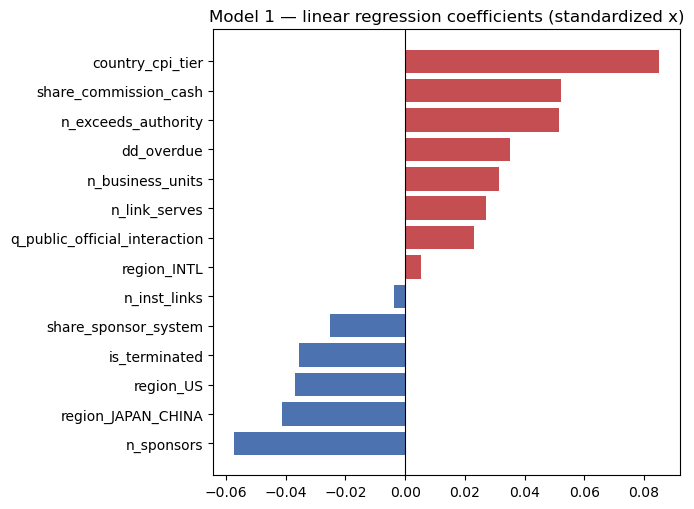

In [10]:
model_lin = run_model("1_linear_regression")
yhat = model_lin.predict(Xte_s)
print(f"y_hat on TEST: min={yhat.min():.2f}, max={yhat.max():.2f}, "
      f"share outside [0,1] = {np.mean((yhat < 0) | (yhat > 1)):.1%}")
coef_lin = pd.Series(model_lin[-1].coef_, index=SELECTED).sort_values()
plt.figure(figsize=(7, 0.3 * len(coef_lin) + 1))
plt.barh(coef_lin.index, coef_lin.values, color=np.where(coef_lin > 0, "#C44E52", "#4C72B0"))
plt.axvline(0, c="k", lw=0.8); plt.title("Model 1 — linear regression coefficients (standardized x)")
plt.tight_layout(); plt.show()

## Model 2: logistic regression

$\log\frac{P}{1-P}=\beta_0+\beta^\top x_i$, with $e^{\beta_j}$ the model's odds ratio for a one-SD increase in the preprocessed feature. `class_weight="balanced"` sets the positive-to-negative weight ratio to the training negative count divided by the training positive count: 674/116 ≈ 5.81 in this split. The ratio varies across folds.

With correlated variables (e.g. `onboard_year` and `tenure_years`), individual coefficient signs can be misleading. Because the fit uses class weights, its probability output should be treated as a ranking score unless calibration is separately validated.


In [11]:
model_logit = run_model("2_logistic_regression")
coef_logit = pd.DataFrame({"coef": model_logit[-1].coef_.ravel()}, index=SELECTED)
coef_logit["odds_ratio"] = np.exp(coef_logit.coef)
display(coef_logit.sort_values("coef", key=np.abs, ascending=False).round(3))

2_logistic_regression: 14 variables | TEST (4:1) | random-guess AP_case = AP = 0.203


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
2_logistic_regression,0.724,0.513,0.74,0.488,0.581,0.576,0.442,0.5,0.715


,coef,odds_ratio
region_US,-1.098,0.334
n_sponsors,-0.886,0.412
share_sponsor_system,-0.836,0.434
n_exceeds_authority,0.826,2.285
country_cpi_tier,0.770,2.159
region_JAPAN_CHINA,-0.669,0.512
is_terminated,-0.453,0.636
share_commission_cash,0.437,1.548
n_inst_links,0.416,1.515
n_business_units,0.383,1.466


## Model 3: decision tree
Handles thresholds and interactions and can be plotted. Unstable, and the scores take only a few distinct values, so lots of ties (broken at random).

3_decision_tree: 14 variables | TEST (4:1) | random-guess AP_case = AP = 0.203


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
3_decision_tree,0.539,0.432,0.699,0.465,0.674,0.48,0.279,0.353,0.657


inner-CV PR-AUC by max_depth: {2: 0.4, 3: 0.473, 4: 0.527, 5: 0.577, 6: 0.557} -> chosen 5


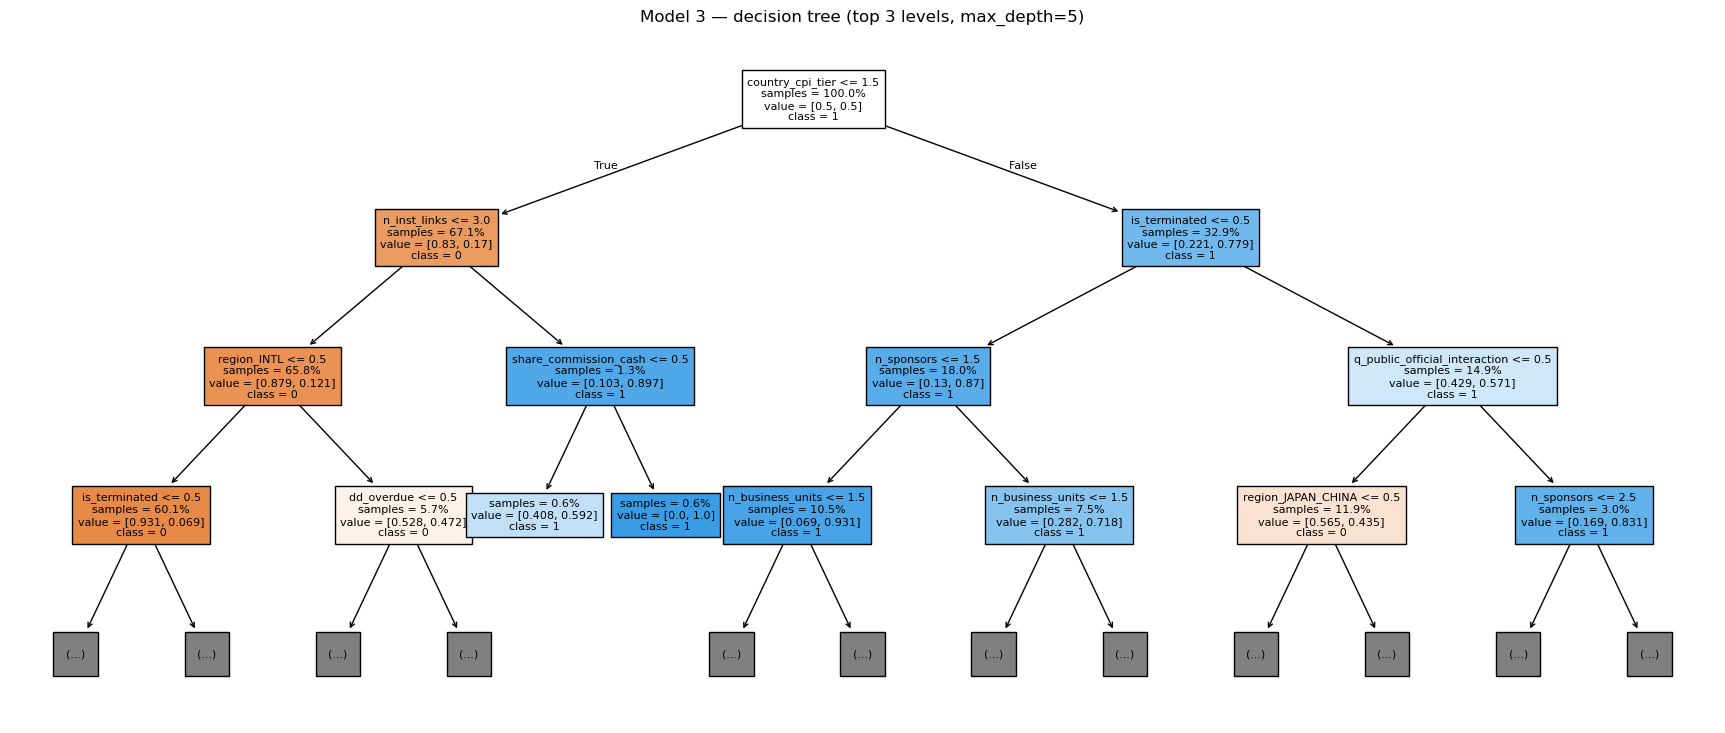

In [12]:
model_tree = run_model("3_decision_tree")
print("inner-CV PR-AUC by max_depth:", {k: round(v, 3) for k, v in model_tree.depth_cv_.items()},
      "-> chosen", model_tree.best_depth_)
plt.figure(figsize=(22, 9))
plot_tree(model_tree[-1], feature_names=SELECTED, class_names=["0", "1"], filled=True,
          max_depth=3, fontsize=8, impurity=False, proportion=True)
plt.title(f"Model 3 — decision tree (top 3 levels, max_depth={model_tree.best_depth_})"); plt.show()

## Model 4: random forest
Interpreted with permutation importance on the test part (drop in AP when one variable is shuffled).

4_random_forest: 14 variables | TEST (4:1) | random-guess AP_case = AP = 0.203


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
4_random_forest,0.663,0.481,0.734,0.442,0.581,0.632,0.279,0.387,0.682


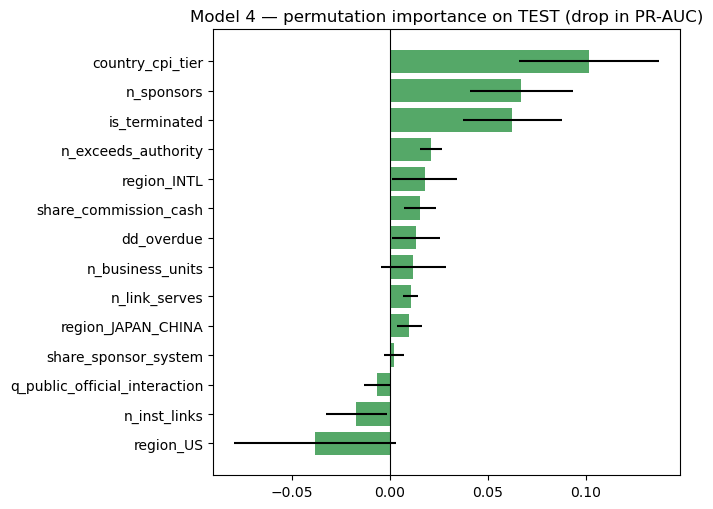

In [13]:
model_rf = run_model("4_random_forest")
pi = permutation_importance(model_rf, Xte_s, yte, scoring="average_precision", n_repeats=20, random_state=SEED)
imp_rf = pd.Series(pi.importances_mean, index=SELECTED).sort_values()
plt.figure(figsize=(7, 0.3 * len(imp_rf) + 1))
plt.barh(imp_rf.index, imp_rf.values, xerr=pi.importances_std[np.argsort(pi.importances_mean)], color="#55A868")
plt.axvline(0, c="k", lw=0.8); plt.title("Model 4 — permutation importance on TEST (drop in PR-AUC)")
plt.tight_layout(); plt.show()

## Model 5: gradient boosting
`HistGradientBoosting`: depth 3, learning rate 0.05, a maximum of 300 boosting iterations.

In [14]:
model_gb = run_model("5_gradient_boosting")

5_gradient_boosting: 14 variables | TEST (4:1) | random-guess AP_case = AP = 0.203


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1,threshold
model,,,,,,,,,
5_gradient_boosting,0.69,0.461,0.684,0.465,0.535,0.533,0.186,0.276,0.764


## The five models on the same split

This comparison uses 212 test records, including 43 positives in 6 positive case groups, so the estimates are noisy. Linear regression has the highest `AP_case` on this split (0.744), followed by logistic regression (0.724). Model conclusions should rely on the repeated evaluation below rather than this single split.


,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,precision,recall,f1
model,,,,,,,,
1_linear_regression,0.744,0.544,0.800,0.488,0.674,0.477,0.488,0.483
2_logistic_regression,0.724,0.513,0.740,0.488,0.581,0.576,0.442,0.500
3_decision_tree,0.539,0.432,0.699,0.465,0.674,0.480,0.279,0.353
4_random_forest,0.663,0.481,0.734,0.442,0.581,0.632,0.279,0.387
5_gradient_boosting,0.690,0.461,0.684,0.465,0.535,0.533,0.186,0.276


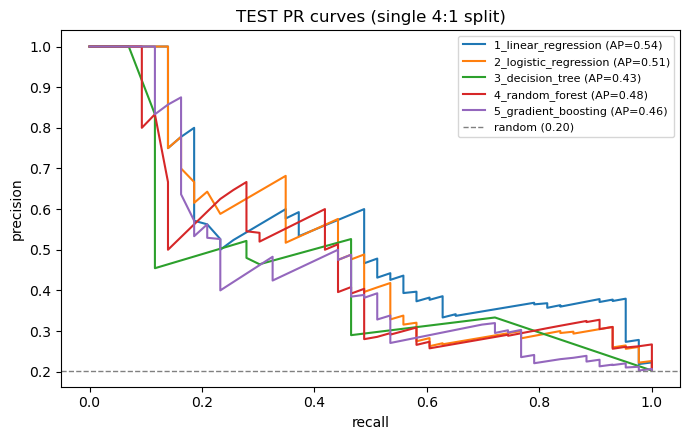

In [15]:
res = pd.DataFrame(RESULTS).set_index("model")
res.to_csv(f"{OUT}/L1_models_test_metrics.csv")
display(res[["AP_case", "AP", "roc_auc", "precision_at_k", "recall_at_2k", "precision", "recall", "f1"]].round(3))
plt.figure(figsize=(7, 4.5))
for name, s in TEST_SCORES.items():
    p, r_, _ = precision_recall_curve(yte, s)
    plt.plot(r_, p, label=f"{name} (AP={average_precision_score(yte, s):.2f})")
plt.axhline(yte.mean(), ls="--", c="grey", lw=1, label=f"random ({yte.mean():.2f})")
plt.xlabel("recall"); plt.ylabel("precision"); plt.title("TEST PR curves (single 4:1 split)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

# Unsupervised Learning: Isolation Forest

The main dataset (~20,000 records) has no labels and may contain patterns that are not in the practice set, so we also try a label-free method.

- uses all available variables in the evaluated version, without supervised variable selection
- fitted on all 1,002 records, no y
- fixed settings, not tuned against the labels

## Preprocessing
- winsorizing + median imputation fitted on all records
- non-negative continuous variables with skew > 2 → $\log(1+x)$, so a long tail doesn't squeeze most records into a small range

Comparisons with a peer group (e.g. percentiles within the subregion) depend on other vendors, so they're left for Layer 2.

In [16]:
def unsup_matrix(names):
    # no labels used
    Xu = pd.DataFrame(Prep().fit_transform(df[names].values.astype(float)), columns=names)
    cont_ = [c for c in names if Xu[c].nunique() > 2]
    skew_ = [c for c in cont_ if Xu[c].min() >= 0 and Xu[c].skew() > 2]
    Xu[skew_] = np.log1p(Xu[skew_])
    return Xu, cont_, skew_


XU, cont, skewed = unsup_matrix(FEATS)
print(f"{len(FEATS)} variables: {len(FEATS) - len(cont)} binary, {len(cont)} continuous, {len(skewed)} log-transformed")

92 variables: 41 binary, 51 continuous, 26 log-transformed


## Model 6: Isolation Forest

Anomaly score = `-score_samples` (higher = easier to isolate); it is not a calibrated risk probability. The model uses 500 trees and `max_samples=256`. This exploratory section averages scores over 10 random seeds and checks agreement between runs. The later five-seed evaluation averages 5 Isolation Forest fits per evaluation seed.

For the top 10 records, the variables with the largest absolute standardized deviations (|z|) are listed as descriptive context. These deviations are not model-specific feature attributions.


In [17]:
from scipy.stats import spearmanr


def iforest(Xu, seeds=range(10)):
    S = np.array([-IsolationForest(n_estimators=500, max_samples=256, contamination="auto",
                                   random_state=s).fit(Xu).score_samples(Xu) for s in seeds])
    return S.mean(0), S


IF_SCORE, S = iforest(XU.values)
rho = [spearmanr(S[i], S[j])[0] for i in range(len(S)) for j in range(i + 1, len(S))]
IF_ROWS = [dict(scope="ALL 1002", **rank_metrics(y_all, IF_SCORE, w=W_all), seed_spearman=np.mean(rho)),
           dict(scope="TEST 201", **rank_metrics(yte, IF_SCORE[te_idx], w=case_weights(te_idx)))]
display(pd.DataFrame(IF_ROWS).set_index("scope").round(3))

Z = pd.DataFrame(StandardScaler().fit_transform(XU), columns=FEATS, index=features_L1.record_id)
expl = []
for i in np.argsort(-IF_SCORE)[:10]:
    z = Z.iloc[i]
    big = z.abs().sort_values(ascending=False).head(4)
    expl.append(dict(record_id=Z.index[i], y=y_all[i], score=round(IF_SCORE[i], 3),
                     top_deviations=", ".join(f"{k} ({z[k]:+.1f}σ)" for k in big.index)))
print("\nTop-10 most anomalous records")
display(pd.DataFrame(expl))

,AP_case,AP,roc_auc,precision_at_k,recall_at_2k,seed_spearman
scope,,,,,,
ALL 1002,0.357,0.237,0.637,0.270,0.447,0.986
TEST 201,0.479,0.317,0.693,0.349,0.628,NaN



Top-10 most anomalous records


,record_id,y,score,top_deviations
0,TP-DA53581D,0,0.571,"n_link_serves (+5.8σ), n_inst_links (+4.7σ), s..."
1,TP-4F739F22,0,0.566,"share_sponsor_missing (+4.5σ), share_pcard_exp..."
2,TP-5CFFFE15,0,0.564,"n_links_foreign (+21.6σ), n_eng_markets (+7.9σ..."
3,TP-550FB531,1,0.560,"n_expense_classes (+5.0σ), n_service_rows (+3...."
4,TP-98B17648,1,0.559,"n_link_serves (+5.8σ), n_inst_links (+4.7σ), r..."
5,TP-9FC24EA5,1,0.558,"n_link_serves (+5.8σ), n_inst_links (+4.7σ), s..."
6,TP-C41EB24E,1,0.550,"n_links_foreign (+12.2σ), adverse_media (+6.7σ..."
7,TP-74943F49,0,0.544,"n_link_serves (+5.8σ), n_inst_links (+4.7σ), n..."
8,TP-9FC42332,0,0.543,"expert_regulatory_access (+9.1σ), addr_coworki..."
9,TP-E0C9DD5E,0,0.535,"n_approver_is_sponsor (+6.5σ), tenure_years (+..."


---
# Evaluation over 5 seeds + ablations

## Red-flag rule: payments after termination

CASE-0016 is "terminated, but payments continue". Only one vendor out of 1,002 has a positive `n_months_paid_after_term`. When that vendor is held out, the training set contains no positive example of this particular feature, making the signal difficult to learn directly. We therefore evaluate a separate rule using the vendor's own payments and termination date.

**Rule:** flag a vendor if it is paid in month ≥ termination month + `GRACE_MONTHS` + 1 (`GRACE_MONTHS = 1`):
- the termination month itself is skipped, payments are monthly totals
- one grace month for the final invoice

The CASE-0016 vendor was terminated on 2025-01-25 and has one paid month after that, 2025-03 (`why_flagged` says "3 more month(s)"). With 2 grace months it would not be flagged. The one-month choice was informed by this labelled example, so its measured gain is exploratory rather than an independent validation of the rule. On the main data we need to check how many vendors it flags; some may be legitimate (e.g. transitional services around the consumer healthcare demerger in `business_events`).

**Ranking:** rank percentile of the score + 2 for flagged vendors, i.e. flagged vendors first, then everyone else by score. Results are reported with and without the rule.

In [18]:
from scipy.stats import rankdata

GRACE_MONTHS = 1
_term = tp.set_index("record_id").terminated_date
_pm = pay.groupby("record_id").month.apply(lambda s: sorted(set(s.dt.to_period("M"))))


def last_paid_offset_after_termination(r):
    # months from termination month to last paid month (0 if none)
    t = _term.get(r)
    if pd.isna(t):
        return 0
    offs = [(m - t.to_period("M")).n for m in _pm.get(r, [])]
    offs = [o for o in offs if o > 0]
    return max(offs) if offs else 0


rid_all = df.record_id.values
PAY_OFFSET = pd.Series({r: last_paid_offset_after_termination(r) for r in rid_all})
case_of_all = {m: c.case_id for c in labels.itertuples() for m in c.members}
print("vendors flagged by grace period (payment in month >= termination month + grace + 1):")
display(pd.DataFrame([dict(grace_months=gm, rule=f"paid in month >= termination month + {gm + 1}",
                           n_flagged=int((PAY_OFFSET >= gm + 1).sum()),
                           flagged=", ".join(f"{r} ({case_of_all.get(r, 'not a case member')})"
                                             for r in PAY_OFFSET[PAY_OFFSET >= gm + 1].index))
                      for gm in [0, 1, 2]]))
RED_FLAG = (PAY_OFFSET.reindex(rid_all).values >= GRACE_MONTHS + 1)
print(f"GRACE_MONTHS = {GRACE_MONTHS} -> {RED_FLAG.sum()} red-flag vendor(s)")


def apply_rule(s):
    # flagged vendors on top
    return rankdata(s) / len(s) + 2.0 * RED_FLAG

vendors flagged by grace period (payment in month >= termination month + grace + 1):


,grace_months,rule,n_flagged,flagged
0,0,paid in month >= termination month + 1,1,TP-33FC40CA (CASE-0016)
1,1,paid in month >= termination month + 2,1,TP-33FC40CA (CASE-0016)
2,2,paid in month >= termination month + 3,0,


GRACE_MONTHS = 1 -> 1 red-flag vendor(s)


## Evaluation setup

Every record receives a score under one of two evaluation protocols:

- **Models 1–5:** out-of-fold predictions from grouped 5-fold CV. Variable selection is redone within each outer training set, the model is refitted (the tree reselects its depth), and the held-out fold is scored without using its labels for fitting.
- **Isolation Forest:** label-free fitting and scoring on all 1,002 records. This is a full-population, transductive anomaly ranking, not an out-of-fold or future-record generalization estimate.

The supervised evaluation uses five different fold splits. Isolation Forest uses a different five-fit seed ensemble for each evaluation seed. Results are reported as mean [min–max]; these ranges describe variation across the five runs and are not confidence intervals. The evaluation uses one snapshot and does not establish performance on future periods.

Metrics:

- `AP_case`: case-balanced record-level AP; `AP`: ordinary record-level AP.
- `P@k`, `R@k` for k = 10, 25, 50, 100: precision and recall over records.
- `cases_half@k`: number of the 33 labelled cases with at least half of their members among the top k records (k = 50, 100, 159). This is a member-coverage diagnostic, not evaluation of predicted case groups, IoU, or one-to-one matching. The budget of 159 uses the known positive count and is a reference only.
- Coverage by typology: the fraction of labelled cases of each typology meeting the half-members-in-top-159 criterion. Outputs label this as case recall, but it is the same member-coverage diagnostic.

Each model is scored with and without the red-flag rule. `run_version(names, tag)` runs five outer splits for each of five evaluation seeds for supervised models, plus the corresponding Isolation Forest ensembles. The rule uses a grace period informed by the practice labels, so the hybrid results remain exploratory even though the underlying supervised scores are out of fold.


In [19]:
rid = df.record_id.values
case_mem = {c.case_id: set(c.members) for c in labels.itertuples()}
case_typ = dict(zip(labels.case_id, labels.typology_tags))
n_pos = int(y_all.sum())
KS, KS_CASE = [10, 25, 50, 100], [50, 100, 159]
SEEDS = list(range(N_SEEDS))
ALL_MODELS = MODELS + ["6_isolation_forest"]


def _fold(Xv, names, tr, te):
    _, _, v3, _, _ = select_variables(Xv[tr], y_all[tr], g_all[tr], names, verbose=False)
    ix = [names.index(v) for v in v3]
    out = {m: get_score(fit_model(m, Xv[tr][:, ix], y_all[tr], g_all[tr]), Xv[te][:, ix]) for m in MODELS}
    return te, v3, out


def eval_scores(s, seed):
    r = np.random.default_rng(seed)
    order = np.argsort(-(s + 1e-9 * r.random(len(s))))
    d = {"AP_case": average_precision_score(y_all, s, sample_weight=W_all), "AP": average_precision_score(y_all, s)}
    for k in KS:
        d[f"P@{k}"] = y_all[order[:k]].mean()
        d[f"R@{k}"] = y_all[order[:k]].sum() / n_pos
    for k in KS_CASE:
        top = set(rid[order[:k]])
        d[f"cases_half@{k}"] = sum(len(m & top) / len(m) >= 0.5 for m in case_mem.values())
    top = set(rid[order[:n_pos]])
    per_case = {cid: float(len(m & top) / len(m) >= 0.5) for cid, m in case_mem.items()}
    return d, per_case


FROZEN = {"oof": [], "selected": []}     # filled by run_version, saved at the end


def run_version(names, tag):
    Xv = df[names].values.astype(float)
    Xu_v = unsup_matrix(names)[0].values
    rows, cases, sels = [], [], []
    for seed in SEEDS:
        folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=1000 + seed).split(Xv, y_all, g_all))
        res_ = Parallel(n_jobs=N_JOBS)(delayed(_fold)(Xv, names, tr, te) for tr, te in folds)
        S = {m: np.full(len(y_all), np.nan) for m in MODELS}
        fold_id = np.full(len(y_all), -1)
        for f_, (te, v3, out) in enumerate(res_):
            sels.append(v3)
            fold_id[te] = f_
            FROZEN["selected"].append(dict(version=tag, seed=seed, fold=f_, n_vars=len(v3), variables=v3))
            for m in MODELS:
                S[m][te] = out[m]
        S["6_isolation_forest"] = iforest(Xu_v, seeds=range(seed * 10, seed * 10 + 5))[0]
        FROZEN["oof"].append(pd.DataFrame({"version": tag, "seed": seed, "record_id": rid, "y": y_all,
                                           "group_id": g_all, "fold": fold_id, "red_flag": RED_FLAG.astype(int),
                                           **{f"score_{m}": S[m] for m in ALL_MODELS}}))
        for m in ALL_MODELS:
            nv = np.mean([len(v) for v in sels[-5:]]) if m in MODELS else len(names)
            for rule in (False, True):
                d, pc = eval_scores(apply_rule(S[m]) if rule else S[m], seed)
                rows.append(dict(version=tag, rule=rule, model=m, seed=seed, n_vars_mean=nv, **d))
                cases.append(dict(version=tag, rule=rule, model=m, seed=seed, **pc))
        print(f"  [{tag}] seed {seed + 1}/{len(SEEDS)} done")
    return pd.DataFrame(rows), pd.DataFrame(cases), sels


def summarize(rows):
    cols = ["AP_case", "AP"] + [f"P@{k}" for k in KS] + [f"R@{k}" for k in KS] + [f"cases_half@{k}" for k in KS_CASE]
    g = rows.groupby(["version", "rule", "model"], sort=False)[cols]
    mean, lo, hi = g.mean(), g.min(), g.max()
    fmt = mean.copy().astype(object)
    for c in cols:
        nd = 1 if c.startswith("cases") else 3
        fmt[c] = [f"{a:.{nd}f} [{b:.{nd}f}–{e:.{nd}f}]" for a, b, e in zip(mean[c], lo[c], hi[c])]
    return mean, fmt


def typology_table(cases):
    long = cases.melt(id_vars=["version", "rule", "model", "seed"], var_name="case_id", value_name="hit")
    long = long.assign(typology=long.case_id.map(case_typ).str.split("|")).explode("typology")
    return long.groupby(["version", "rule", "model", "typology"]).hit.mean().unstack("typology")


print("random baseline: AP_case = AP ≈", round(y_all.mean(), 3), "| cases_half@159 ≈ 3 (random ranking)")

random baseline: AP_case = AP ≈ 0.159 | cases_half@159 ≈ 3 (random ranking)


## Full version, 5 seeds

Report mean [min–max] across the five evaluation seeds. The full-dataset positive fraction of 15.9% is a reference level for AP and expected random P@k, rather than an exact finite-sample expectation for either AP measure.

1. Record-ranking and case-member-coverage metrics without the rule.
2. Before / after comparison for the red-flag rule.
3. Coverage by typology: fraction of cases with at least half their members in the top 159 records.
4. Feature-selection frequency over the 25 outer folds, as a measure of selection stability.


  [full] seed 1/5 done


/opt/homebrew/Caskroom/miniforge/base/envs/pyarm/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/homebrew/Caskroom/miniforge/base/envs/pyarm/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


  [full] seed 2/5 done
  [full] seed 3/5 done
  [full] seed 4/5 done
  [full] seed 5/5 done
time: 4.6 min

FULL version, NO rule — mean [min–max] over seeds


,AP_case,AP,P@10,P@25,P@50,P@100,R@10,R@25,R@50,R@100,cases_half@50,cases_half@100,cases_half@159
model,,,,,,,,,,,,,
1_linear_regression,0.577 [0.533–0.599],0.515 [0.467–0.536],0.860 [0.700–0.900],0.840 [0.760–0.880],0.692 [0.580–0.780],0.592 [0.540–0.640],0.054 [0.044–0.057],0.132 [0.119–0.138],0.218 [0.182–0.245],0.372 [0.340–0.403],7.8 [7.0–8.0],16.0 [15.0–18.0],20.6 [19.0–22.0]
2_logistic_regression,0.563 [0.515–0.599],0.521 [0.455–0.596],0.900 [0.900–0.900],0.896 [0.840–0.920],0.764 [0.680–0.820],0.594 [0.490–0.670],0.057 [0.057–0.057],0.141 [0.132–0.145],0.240 [0.214–0.258],0.374 [0.308–0.421],9.0 [7.0–10.0],14.8 [13.0–17.0],20.6 [19.0–22.0]
3_decision_tree,0.464 [0.412–0.562],0.428 [0.396–0.533],0.780 [0.600–0.900],0.720 [0.600–0.880],0.604 [0.500–0.760],0.544 [0.440–0.650],0.049 [0.038–0.057],0.113 [0.094–0.138],0.190 [0.157–0.239],0.342 [0.277–0.409],6.6 [5.0–8.0],13.0 [9.0–15.0],19.0 [17.0–22.0]
4_random_forest,0.522 [0.464–0.569],0.488 [0.424–0.550],0.700 [0.500–1.000],0.664 [0.480–0.840],0.672 [0.520–0.820],0.632 [0.570–0.700],0.044 [0.031–0.063],0.104 [0.075–0.132],0.211 [0.164–0.258],0.397 [0.358–0.440],6.8 [6.0–8.0],14.8 [13.0–16.0],19.8 [17.0–21.0]
5_gradient_boosting,0.583 [0.488–0.645],0.536 [0.459–0.607],0.980 [0.900–1.000],0.896 [0.720–0.960],0.772 [0.640–0.880],0.638 [0.560–0.690],0.062 [0.057–0.063],0.141 [0.113–0.151],0.243 [0.201–0.277],0.401 [0.352–0.434],8.0 [6.0–9.0],14.0 [12.0–15.0],20.0 [19.0–21.0]
6_isolation_forest,0.361 [0.358–0.365],0.240 [0.238–0.242],0.400 [0.400–0.400],0.288 [0.280–0.320],0.312 [0.300–0.340],0.270 [0.260–0.280],0.025 [0.025–0.025],0.045 [0.044–0.050],0.098 [0.094–0.107],0.170 [0.164–0.176],7.6 [7.0–8.0],9.6 [9.0–10.0],11.8 [11.0–12.0]



Before / after the red-flag rule (mean over seeds)


,AP_case | no rule,AP_case | with rule,AP_case | change,AP | no rule,AP | with rule,AP | change,cases_half@159 | no rule,cases_half@159 | with rule,cases_half@159 | change
model,,,,,,,,,
1_linear_regression,0.577,0.614,0.038,0.515,0.524,0.009,20.6,21.6,1.0
2_logistic_regression,0.563,0.597,0.035,0.521,0.528,0.007,20.6,21.6,1.0
3_decision_tree,0.464,0.506,0.042,0.428,0.436,0.009,19.0,19.8,0.8
4_random_forest,0.522,0.566,0.044,0.488,0.497,0.010,19.8,20.8,1.0
5_gradient_boosting,0.583,0.618,0.035,0.536,0.543,0.007,20.0,21.0,1.0
6_isolation_forest,0.361,0.405,0.044,0.240,0.252,0.012,11.8,12.8,1.0



Case recall by typology (share of cases with >= half members in the top 159; mean over seeds)


model,1_linear_regression,2_logistic_regression,3_decision_tree,4_random_forest,5_gradient_boosting,6_isolation_forest,n_cases
typology,,,,,,,
COMMON_BENEFICIAL_OWNER,0.70,0.75,0.60,0.65,0.57,0.25,8
OWNERSHIP_OPERATIONAL_OVERLAP,0.60,0.60,0.28,0.32,0.28,0.20,5
ACTIVITY_TIMING_CONCENTRATION,0.50,0.45,0.50,0.45,0.45,0.00,4
SHARED_ADDRESS,1.00,1.00,0.95,0.95,0.90,0.50,4
SPONSOR_APPROVER_COUPLING,0.55,0.60,0.55,0.50,0.50,0.25,4
BRIDGE_ENTITY,0.47,0.47,0.40,0.33,0.53,0.67,3
DENSE_MULTI_RELATION_CLUSTER,0.93,1.00,0.80,0.93,0.93,0.00,3
LAYERED_COMPLEX_OWNERSHIP,0.33,0.27,0.47,0.33,0.40,0.67,3
OPAQUE_JURISDICTION_ROUTING,1.00,0.93,1.00,1.00,1.00,1.00,3


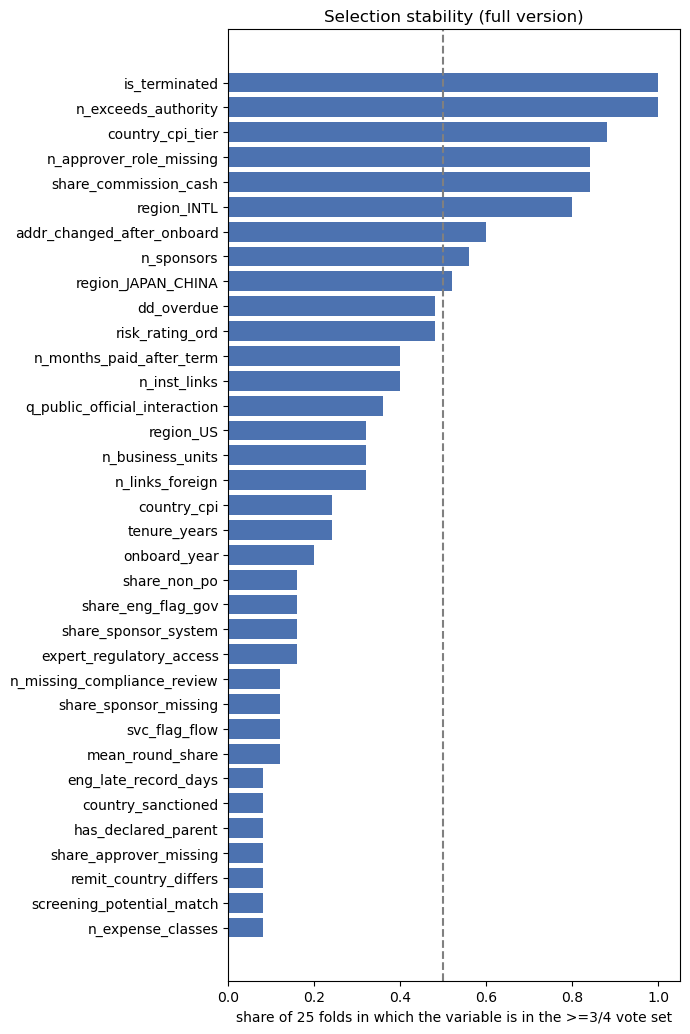

In [20]:
import time
t0 = time.time()
rows_full, cases_full, sels_full = run_version(FEATS, "full")
print(f"time: {(time.time() - t0) / 60:.1f} min")

mean_full, fmt_full = summarize(rows_full)
print("\nFULL version, NO rule — mean [min–max] over seeds")
display(fmt_full.xs(False, level="rule").droplevel("version"))

ba = mean_full[["AP_case", "AP", "cases_half@159"]].droplevel("version").unstack("rule")
ba.columns = [f"{m} | {'with rule' if r else 'no rule'}" for m, r in ba.columns]
for m in ["AP_case", "AP", "cases_half@159"]:
    ba[f"{m} | change"] = ba[f"{m} | with rule"] - ba[f"{m} | no rule"]
print("\nBefore / after the red-flag rule (mean over seeds)")
display(ba[[c for m in ["AP_case", "AP", "cases_half@159"] for c in ba.columns if c.startswith(m + " |")]].round(3))

typ_full = typology_table(cases_full).loc[("full", False)]
print("\nCase recall by typology (share of cases with >= half members in the top 159; mean over seeds)")
n_cases_typ = pd.Series([t for v in case_typ.values() for t in v.split("|")]).value_counts()
display(typ_full.T.assign(n_cases=n_cases_typ).sort_values("n_cases", ascending=False).round(2))

stab = pd.Series([v for s in sels_full for v in s]).value_counts() / len(sels_full)
stab = stab.reindex(FEATS).fillna(0).sort_values(ascending=False)
stab.rename("selection_frequency").to_csv(f"{OUT}/L1_selection_stability.csv")
rows_full.to_csv(f"{OUT}/L1_full_seed_metrics.csv", index=False)
cases_full.to_csv(f"{OUT}/L1_full_seed_cases.csv", index=False)
top = stab[stab > 0].head(35)[::-1]
plt.figure(figsize=(7, 0.27 * len(top) + 1))
plt.barh(top.index, top.values, color="#4C72B0")
plt.axvline(0.5, ls="--", c="grey")
plt.xlabel(f"share of {len(sels_full)} folds in which the variable is in the >=3/4 vote set")
plt.title("Selection stability (full version)"); plt.tight_layout()
plt.savefig(f"{OUT}/L1_selection_stability.png", dpi=130); plt.show()

## Paired model comparison

Within each seed the supervised models use the same outer folds, so we compare per-seed differences and count how many of the five are positive. Here LR means logistic regression; linear regression is reported separately. Five repeated splits of the same dataset provide descriptive comparisons, not independent replications or a significance test.

Metrics: `AP_case`, record P@10 / 25 / 50 / 100, and `cases_half@159`. This comparison excludes the red-flag rule to isolate model rankings. The same rule is applied to each model elsewhere, but its effect on metrics depends on the original ranking and is not identical across models.


In [21]:
base = rows_full[~rows_full.rule]
pairs = [("5_gradient_boosting", "2_logistic_regression", "GB − LR"),
         ("4_random_forest", "2_logistic_regression", "RF − LR"),
         ("5_gradient_boosting", "4_random_forest", "GB − RF")]
out = []
for metric in ["AP_case", "P@10", "P@25", "P@50", "P@100", "cases_half@159"]:
    pv = base.pivot(index="seed", columns="model", values=metric)
    for a_, b_, lab_ in pairs:
        d_ = pv[a_] - pv[b_]
        out.append(dict(metric=metric, pair=lab_, **{f"seed {s}": round(v, 3) for s, v in d_.items()},
                        mean=round(d_.mean(), 3), n_positive=f"{int((d_ > 0).sum())} / {len(d_)}"))
paired = pd.DataFrame(out)
paired.to_csv(f"{OUT}/L1_paired_model_comparison.csv", index=False)
display(paired)

,metric,pair,seed 0,seed 1,seed 2,seed 3,seed 4,mean,n_positive
0,AP_case,GB − LR,0.040,0.016,0.027,-0.027,0.046,0.020,4 / 5
1,AP_case,RF − LR,-0.048,-0.093,-0.003,-0.018,-0.041,-0.041,0 / 5
2,AP_case,GB − RF,0.088,0.109,0.030,-0.008,0.087,0.061,4 / 5
3,P@10,GB − LR,0.100,0.100,0.100,0.000,0.100,0.080,4 / 5
4,P@10,RF − LR,-0.300,-0.400,0.100,-0.100,-0.300,-0.200,1 / 5
5,P@10,GB − RF,0.400,0.500,0.000,0.100,0.400,0.280,4 / 5
6,P@25,GB − LR,0.040,0.000,0.040,-0.120,0.040,-0.000,3 / 5
7,P@25,RF − LR,-0.240,-0.440,-0.080,-0.200,-0.200,-0.232,0 / 5
8,P@25,GB − RF,0.280,0.440,0.120,0.080,0.240,0.232,5 / 5
9,P@50,GB − LR,0.040,-0.040,0.020,-0.040,0.060,0.008,3 / 5


## Ablations
Drop one group of variables and rerun everything (same seeds, selection redone in every fold, Isolation Forest refit on the smaller set).

| version | removed |
|---|---|
| −T | `is_terminated`, `tenure_years`, `onboard_year` |
| −T_ext | −T + `onboarded_last_3y`, `dd_overdue` (onboarding date and `status == 'active'` again) |
| −C | the 15 employee / institution / market variables |
| −D | the 8 country / region variables |
| −exceeds_authority | `n_exceeds_authority` |
| −role_missing | `n_approver_role_missing` |
| −authority_both | both (= conservative baseline) |

Tables are without the rule, `AP_case` first. Each difference measures the effect of removing a group and rerunning selection and fitting; it is not the isolated contribution of one feature with the rest of the pipeline held fixed.

Why T: 60% of non-case vendors are terminated vs 18% of case members, and case members were onboarded later. No member of the APPROVER, BRIDGE, DENSE_CLUSTER, SPONSOR_APPROVER_COUPLING or ownership cases is terminated, although none of these typologies is about status. This may reflect the data generator or which vendors remain eligible for later cases. The ablation tests sensitivity to these features; it does not establish the cause of the association.

  [-T] seed 1/5 done


/opt/homebrew/Caskroom/miniforge/base/envs/pyarm/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/homebrew/Caskroom/miniforge/base/envs/pyarm/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


  [-T] seed 2/5 done


/opt/homebrew/Caskroom/miniforge/base/envs/pyarm/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


  [-T] seed 3/5 done


/opt/homebrew/Caskroom/miniforge/base/envs/pyarm/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


... (28 outputs left out)

AP


version,-T,-T_ext,-C,-D,-exceeds_authority,-role_missing,-authority_both
model,,,,,,,
1_linear_regression,-0.001,-0.040,-0.086,0.034,-0.047,-0.004,-0.059
2_logistic_regression,-0.004,-0.018,-0.106,0.064,-0.068,-0.001,-0.080
3_decision_tree,0.001,-0.004,-0.054,0.048,-0.011,-0.019,-0.036
4_random_forest,0.007,-0.038,-0.098,0.135,-0.061,0.015,-0.058
5_gradient_boosting,-0.004,-0.044,-0.143,0.074,-0.106,0.012,-0.077
6_isolation_forest,-0.005,-0.017,-0.033,-0.009,-0.017,-0.010,-0.019


cases_half@159


version,-T,-T_ext,-C,-D,-exceeds_authority,-role_missing,-authority_both
model,,,,,,,
1_linear_regression,-0.4,-3.2,-1.2,-0.4,-0.6,0.2,-0.2
2_logistic_regression,-0.2,-3.2,-1.0,-0.4,-0.8,-1.0,0.0
3_decision_tree,-2.2,-2.6,-1.0,1.8,0.4,0.8,0.0
4_random_forest,-0.6,-3.0,-0.8,3.6,-0.2,0.2,0.6
5_gradient_boosting,-0.8,-3.2,-1.0,1.0,-0.6,0.2,0.2
6_isolation_forest,-0.4,1.2,-3.8,0.2,-0.8,-0.4,-0.6


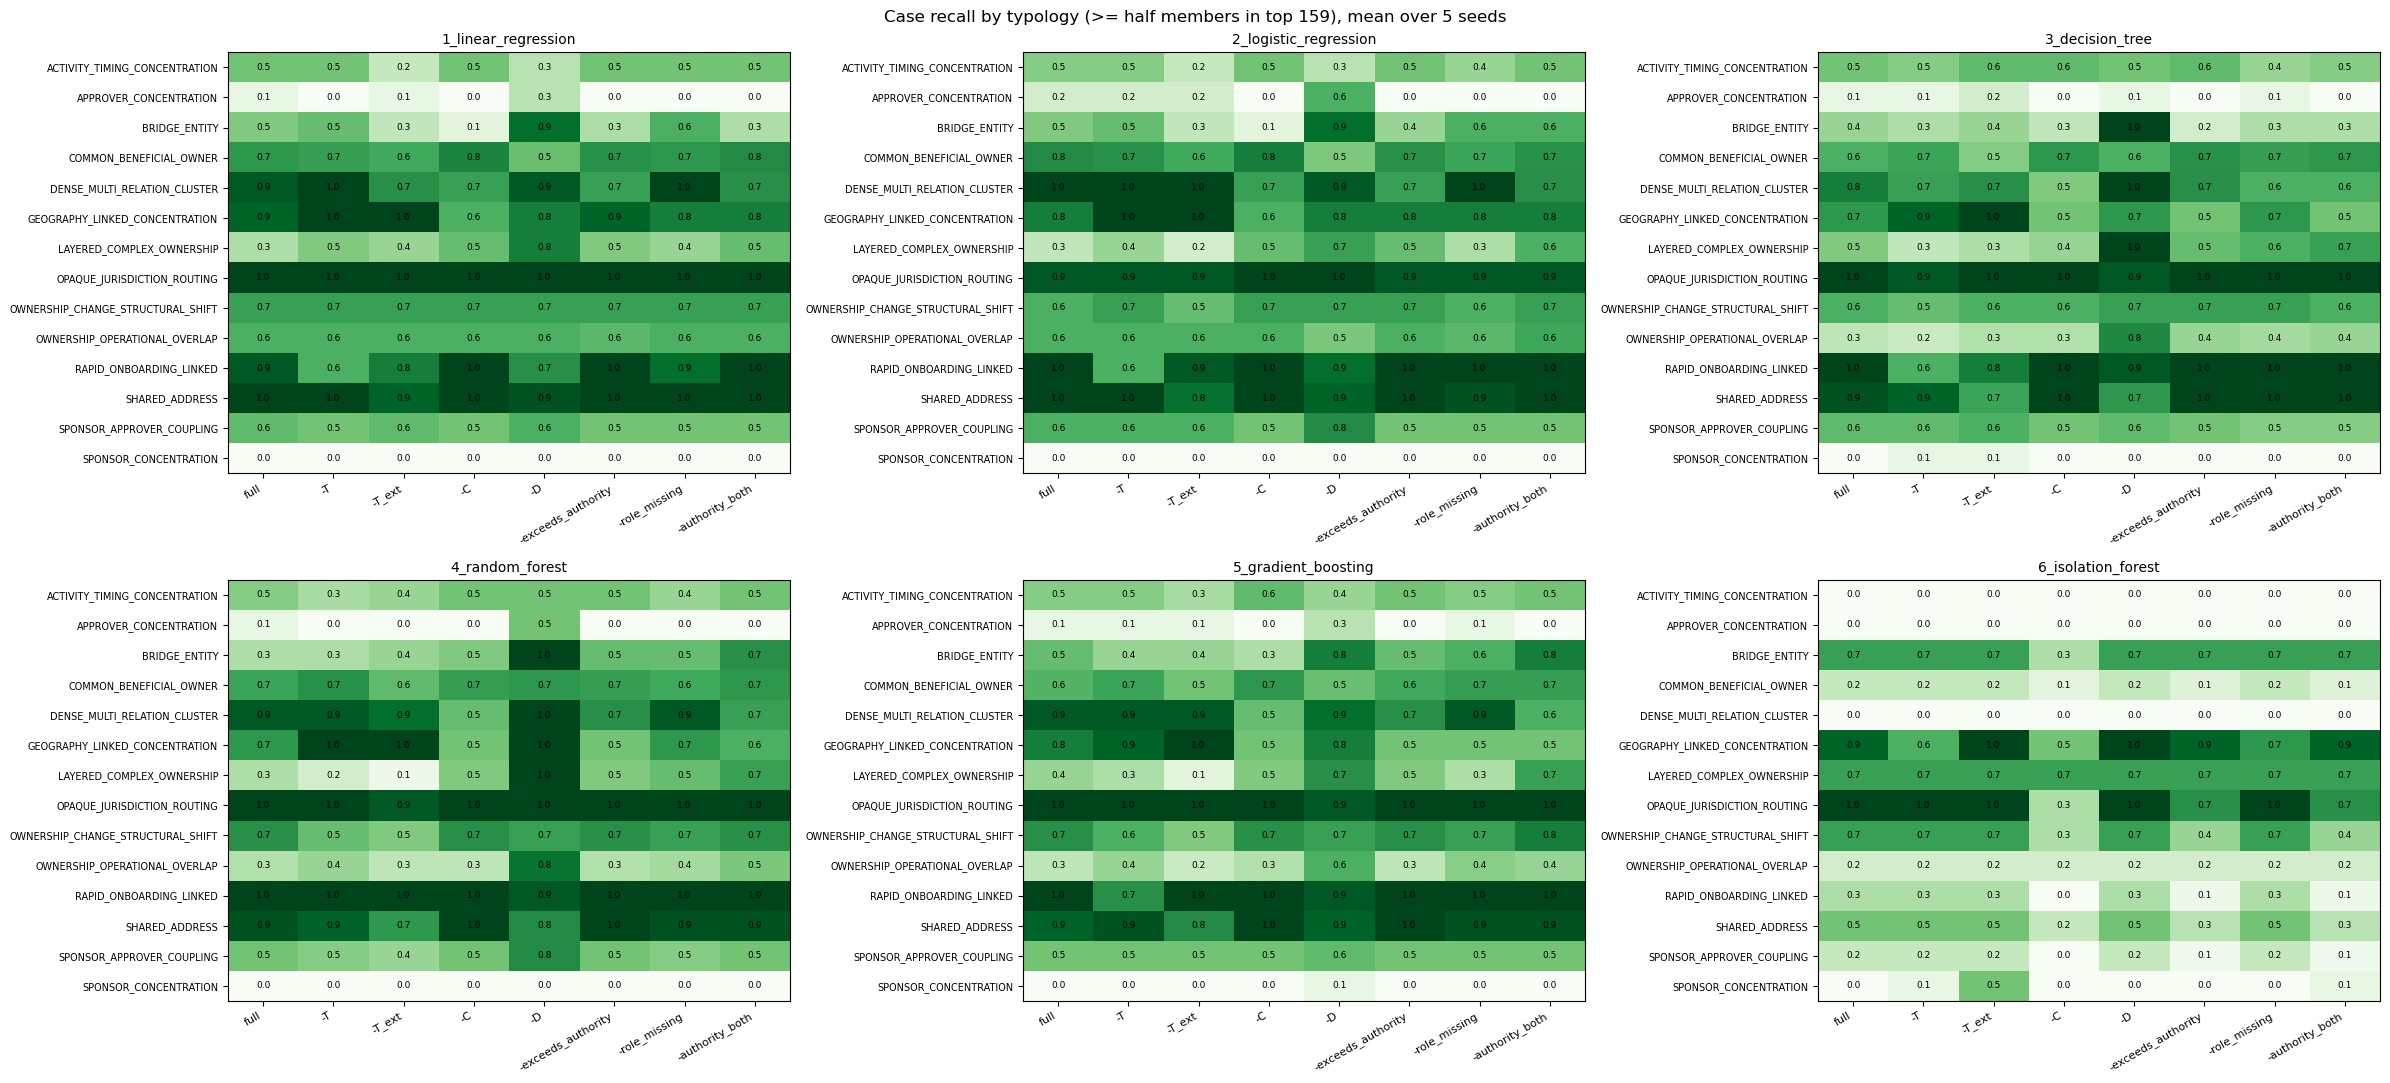

In [22]:
GROUPS = {
    "-T": ["is_terminated", "tenure_years", "onboard_year"],
    "-T_ext": ["is_terminated", "tenure_years", "onboard_year", "onboarded_last_3y", "dd_overdue"],
    "-C": ["n_exceeds_authority", "n_business_units", "n_sponsors", "n_inst_links", "n_link_serves",
           "n_inst_countries", "share_sponsor_system", "share_cross_border", "share_paying_mkt_differs",
           "n_links_foreign", "share_links_public", "n_eng_markets", "n_distinct_approvers", "n_approver_is_sponsor",
           "n_approver_role_missing"],
    "-D": ["country_cpi", "country_cpi_tier", "country_bo_access_low", "country_sanctioned",
           "region_US", "region_EUROPE", "region_JAPAN_CHINA", "region_INTL"],
    "-exceeds_authority": ["n_exceeds_authority"],
    "-role_missing": ["n_approver_role_missing"],
    "-authority_both": ["n_exceeds_authority", "n_approver_role_missing"],
}
for k, v in GROUPS.items():
    missing = [c for c in v if c not in FEATS]
    assert not missing, (k, missing)

all_rows, all_cases = [rows_full], [cases_full]
t0 = time.time()
for tag, drop in GROUPS.items():
    names = [c for c in FEATS if c not in drop]
    r_, c_, _ = run_version(names, tag)
    all_rows.append(r_); all_cases.append(c_)
print(f"time: {(time.time() - t0) / 60:.1f} min")
abl_rows, abl_cases = pd.concat(all_rows), pd.concat(all_cases)
abl_rows.to_csv(f"{OUT}/L1_ablation_seed_metrics.csv", index=False)
abl_cases.to_csv(f"{OUT}/L1_ablation_seed_cases.csv", index=False)

abl_mean, abl_fmt = summarize(abl_rows)
abl_mean, abl_fmt = abl_mean.xs(False, level="rule"), abl_fmt.xs(False, level="rule")
order_v = ["full"] + list(GROUPS)
for c, lab_ in [("AP_case", "AP_case (main)"), ("AP", "AP (record-level)"),
                ("cases_half@159", "cases with >= half members in the top 159")]:
    print(f"\nAblation — {lab_}, mean [min–max] over seeds")
    display(abl_fmt[c].unstack("version")[order_v])
delta = abl_mean[["AP_case", "AP", "cases_half@159"]].unstack("version")
print("\nChange vs full version (mean over seeds)")
for c in ["AP_case", "AP", "cases_half@159"]:
    d_ = delta[c][order_v].sub(delta[c]["full"], axis=0).drop(columns="full")
    print(c); display(d_.round(3))

typ_abl = typology_table(abl_cases).xs(False, level="rule")
typ_abl.to_csv(f"{OUT}/L1_ablation_by_typology.csv")
fig, axes = plt.subplots(2, 3, figsize=(24, 11))
for ax, m in zip(axes.ravel(), ALL_MODELS):
    t = typ_abl.xs(m, level="model").reindex(order_v).T
    im = ax.imshow(t.values, aspect="auto", cmap="Greens", vmin=0, vmax=1)
    ax.set_xticks(range(len(order_v))); ax.set_xticklabels(order_v, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(t.index))); ax.set_yticklabels(t.index, fontsize=7)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5)
    ax.set_title(m, fontsize=10)
fig.suptitle("Case recall by typology (>= half members in top 159), mean over 5 seeds", fontsize=12)
plt.tight_layout(); plt.savefig(f"{OUT}/L1_ablation_typology.png", dpi=130); plt.show()

## Two Layer 1 baselines

- **full**: all Layer 1 variables are eligible for supervised selection. Models 1–5 use the fold-specific selected subset; Isolation Forest uses all variables in this version.
- **conservative**: exclude `n_exceeds_authority` and `n_approver_role_missing` before selection or fitting. This is a sensitivity analysis for unusually clean authority signals, not an established estimate of performance on the main dataset.

Layer 2 can be compared against both using the same splits and metric definitions. Results are shown without and with the rule, followed by the paired model comparison on the conservative version.


In [23]:
KEYS = ["AP_case", "AP", "P@10", "P@25", "P@50", "P@100", "cases_half@159"]
bl_rows = abl_rows[abl_rows.version.isin(["full", "-authority_both"])].replace({"version": {"full": "full", "-authority_both": "conservative"}})
_, bl_fmt = summarize(bl_rows)
for rule in (False, True):
    t = bl_fmt[KEYS].xs(rule, level="rule").unstack("version")
    t.columns = [f"{m} | {v}" for m, v in t.columns]
    print(f"\nLayer 1 baselines — {'WITH' if rule else 'WITHOUT'} the red-flag rule, mean [min–max] over seeds")
    display(t[[f"{m} | {v}" for m in KEYS for v in ["full", "conservative"]]])
bl_rows.to_csv(f"{OUT}/L1_baselines_seed_metrics.csv", index=False)

# paired comparison, conservative baseline
cons = abl_rows[(abl_rows.version == "-authority_both") & (~abl_rows.rule)]
out = []
for metric in ["AP_case", "P@25", "P@50", "P@100", "cases_half@159"]:
    pv = cons.pivot(index="seed", columns="model", values=metric)
    for a_, b_, lab_ in pairs:
        d_ = pv[a_] - pv[b_]
        out.append(dict(metric=metric, pair=lab_, mean=round(d_.mean(), 3), n_positive=f"{int((d_ > 0).sum())} / {len(d_)}"))
print("\nPaired model comparison on the CONSERVATIVE baseline")
display(pd.DataFrame(out))


Layer 1 baselines — WITHOUT the red-flag rule, mean [min–max] over seeds


,AP_case | full,AP_case | conservative,AP | full,AP | conservative,P@10 | full,P@10 | conservative,P@25 | full,P@25 | conservative,P@50 | full,P@50 | conservative,P@100 | full,P@100 | conservative,cases_half@159 | full,cases_half@159 | conservative
model,,,,,,,,,,,,,,
1_linear_regression,0.577 [0.533–0.599],0.560 [0.512–0.594],0.515 [0.467–0.536],0.455 [0.419–0.478],0.860 [0.700–0.900],0.700 [0.700–0.700],0.840 [0.760–0.880],0.680 [0.600–0.720],0.692 [0.580–0.780],0.592 [0.540–0.640],0.592 [0.540–0.640],0.538 [0.510–0.580],20.6 [19.0–22.0],20.4 [20.0–21.0]
2_logistic_regression,0.563 [0.515–0.599],0.530 [0.460–0.558],0.521 [0.455–0.596],0.441 [0.367–0.471],0.900 [0.900–0.900],0.760 [0.700–0.900],0.896 [0.840–0.920],0.696 [0.600–0.760],0.764 [0.680–0.820],0.608 [0.480–0.700],0.594 [0.490–0.670],0.546 [0.500–0.580],20.6 [19.0–22.0],20.6 [19.0–23.0]
3_decision_tree,0.464 [0.412–0.562],0.467 [0.401–0.537],0.428 [0.396–0.533],0.391 [0.349–0.474],0.780 [0.600–0.900],0.620 [0.400–0.900],0.720 [0.600–0.880],0.608 [0.440–0.800],0.604 [0.500–0.760],0.588 [0.520–0.700],0.544 [0.440–0.650],0.530 [0.490–0.580],19.0 [17.0–22.0],19.0 [17.0–20.0]
4_random_forest,0.522 [0.464–0.569],0.499 [0.463–0.538],0.488 [0.424–0.550],0.429 [0.381–0.477],0.700 [0.500–1.000],0.640 [0.400–0.800],0.664 [0.480–0.840],0.704 [0.640–0.720],0.672 [0.520–0.820],0.628 [0.580–0.700],0.632 [0.570–0.700],0.586 [0.550–0.620],19.8 [17.0–21.0],20.4 [19.0–23.0]
5_gradient_boosting,0.583 [0.488–0.645],0.552 [0.516–0.580],0.536 [0.459–0.607],0.459 [0.431–0.512],0.980 [0.900–1.000],0.820 [0.700–0.900],0.896 [0.720–0.960],0.704 [0.640–0.760],0.772 [0.640–0.880],0.660 [0.620–0.700],0.638 [0.560–0.690],0.594 [0.550–0.620],20.0 [19.0–21.0],20.2 [20.0–21.0]
6_isolation_forest,0.361 [0.358–0.365],0.348 [0.341–0.353],0.240 [0.238–0.242],0.221 [0.218–0.223],0.400 [0.400–0.400],0.400 [0.400–0.400],0.288 [0.280–0.320],0.272 [0.240–0.280],0.312 [0.300–0.340],0.268 [0.240–0.300],0.270 [0.260–0.280],0.256 [0.240–0.270],11.8 [11.0–12.0],11.2 [10.0–13.0]



Layer 1 baselines — WITH the red-flag rule, mean [min–max] over seeds


,AP_case | full,AP_case | conservative,AP | full,AP | conservative,P@10 | full,P@10 | conservative,P@25 | full,P@25 | conservative,P@50 | full,P@50 | conservative,P@100 | full,P@100 | conservative,cases_half@159 | full,cases_half@159 | conservative
model,,,,,,,,,,,,,,
1_linear_regression,0.614 [0.575–0.633],0.596 [0.551–0.626],0.524 [0.477–0.545],0.465 [0.428–0.487],0.860 [0.700–0.900],0.740 [0.700–0.800],0.840 [0.760–0.880],0.680 [0.600–0.720],0.696 [0.600–0.780],0.612 [0.560–0.660],0.598 [0.550–0.650],0.546 [0.520–0.580],21.6 [20.0–23.0],21.4 [21.0–22.0]
2_logistic_regression,0.597 [0.552–0.636],0.570 [0.505–0.597],0.528 [0.463–0.604],0.451 [0.379–0.480],0.900 [0.900–0.900],0.820 [0.700–0.900],0.904 [0.840–0.960],0.712 [0.600–0.760],0.772 [0.680–0.840],0.628 [0.500–0.720],0.596 [0.490–0.670],0.548 [0.500–0.580],21.6 [20.0–23.0],21.4 [20.0–24.0]
3_decision_tree,0.506 [0.458–0.593],0.510 [0.448–0.577],0.436 [0.406–0.539],0.401 [0.360–0.483],0.780 [0.600–0.900],0.620 [0.400–0.900],0.760 [0.640–0.920],0.608 [0.440–0.800],0.616 [0.500–0.760],0.604 [0.520–0.720],0.554 [0.450–0.660],0.534 [0.490–0.580],19.8 [18.0–22.0],20.0 [18.0–21.0]
4_random_forest,0.566 [0.514–0.604],0.545 [0.513–0.580],0.497 [0.435–0.557],0.440 [0.392–0.487],0.700 [0.500–1.000],0.640 [0.400–0.800],0.664 [0.480–0.840],0.720 [0.640–0.760],0.676 [0.520–0.820],0.636 [0.600–0.700],0.634 [0.570–0.710],0.594 [0.560–0.630],20.8 [18.0–22.0],21.4 [20.0–24.0]
5_gradient_boosting,0.618 [0.531–0.678],0.590 [0.559–0.615],0.543 [0.467–0.614],0.468 [0.443–0.521],0.980 [0.900–1.000],0.820 [0.700–0.900],0.904 [0.760–0.960],0.728 [0.680–0.800],0.780 [0.640–0.880],0.660 [0.620–0.700],0.642 [0.560–0.700],0.604 [0.560–0.630],21.0 [20.0–22.0],21.2 [21.0–22.0]
6_isolation_forest,0.405 [0.403–0.409],0.392 [0.386–0.397],0.252 [0.250–0.254],0.232 [0.230–0.234],0.500 [0.500–0.500],0.500 [0.500–0.500],0.312 [0.280–0.320],0.304 [0.280–0.320],0.332 [0.320–0.360],0.288 [0.260–0.320],0.278 [0.270–0.290],0.266 [0.250–0.280],12.8 [12.0–13.0],12.2 [11.0–14.0]



Paired model comparison on the CONSERVATIVE baseline


,metric,pair,mean,n_positive
0,AP_case,GB − LR,0.022,3 / 5
1,AP_case,RF − LR,-0.031,1 / 5
2,AP_case,GB − RF,0.053,4 / 5
3,P@25,GB − LR,0.008,2 / 5
4,P@25,RF − LR,0.008,2 / 5
5,P@25,GB − RF,0.000,2 / 5
6,P@50,GB − LR,0.052,4 / 5
7,P@50,RF − LR,0.020,2 / 5
8,P@50,GB − RF,0.032,3 / 5
9,P@100,GB − LR,0.048,5 / 5


## Cases Layer 1 misses

For each case and model, report the fraction of the five seeds in which at least half of the case's members enter the top 159 records. The main table includes the rule; the best supervised coverage frequency without the rule is shown alongside it.

A case becomes a Layer 2 investigation target if every model meets this coverage criterion in fewer than half of the seeds. Failure to meet the criterion does not mean that no individual members were retrieved. These targets are selected using practice labels and motivate relational experiments; improvements on them alone would not demonstrate generalization.


In [24]:
pc0 = cases_full[~cases_full.rule].drop(columns=["version", "rule", "seed"]).groupby("model").mean().T
pc = cases_full[cases_full.rule].drop(columns=["version", "rule", "seed"]).groupby("model").mean().T
pc.insert(0, "typology_tags", pc.index.map(case_typ))
pc.insert(1, "n_members", pc.index.map(lambda c: len(case_mem[c])))
pc["best_supervised"] = pc[MODELS].max(axis=1)
pc["best_supervised_no_rule"] = pc0[MODELS].max(axis=1)
pc = pc.sort_values(["best_supervised", "6_isolation_forest"])
pc.to_csv(f"{OUT}/L1_case_recovery_full.csv")
display(pc.round(2))
targets = pc[(pc.best_supervised < 0.5) & (pc["6_isolation_forest"] < 0.5)]
print(f"\nWITH the red-flag rule: {len(targets)} of {len(pc)} cases are found (>= half members in top 159) in fewer "
      f"than half of the seeds by EVERY model -> Layer 2 target list:")
display(targets[["typology_tags", "n_members", "best_supervised", "best_supervised_no_rule", "6_isolation_forest"]].round(2))

model,typology_tags,n_members,1_linear_regression,2_logistic_regression,3_decision_tree,4_random_forest,5_gradient_boosting,6_isolation_forest,best_supervised,best_supervised_no_rule
CASE-0004,SPONSOR_CONCENTRATION,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CASE-0005,SPONSOR_CONCENTRATION,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CASE-0017,ACTIVITY_TIMING_CONCENTRATION,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CASE-0026,OWNERSHIP_OPERATIONAL_OVERLAP|COMMON_BENEFICIA...,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CASE-0033,BRIDGE_ENTITY|LAYERED_COMPLEX_OWNERSHIP|OWNERS...,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CASE-0006,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,13,0.0,0.2,0.0,0.2,0.0,0.0,0.2,0.2
CASE-0007,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,12,0.2,0.2,0.2,0.0,0.2,0.0,0.2,0.2
CASE-0029,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,3,0.0,0.0,0.2,0.2,0.2,0.0,0.2,0.2
CASE-0021,COMMON_BENEFICIAL_OWNER,4,0.6,0.8,0.8,0.8,0.4,0.0,0.8,0.8
CASE-0012,BRIDGE_ENTITY,1,0.8,0.8,0.0,0.2,0.6,1.0,0.8,0.8



WITH the red-flag rule: 8 of 33 cases are found (>= half members in top 159) in fewer than half of the seeds by EVERY model -> Layer 2 target list:


model,typology_tags,n_members,best_supervised,best_supervised_no_rule,6_isolation_forest
CASE-0004,SPONSOR_CONCENTRATION,10,0.0,0.0,0.0
CASE-0005,SPONSOR_CONCENTRATION,10,0.0,0.0,0.0
CASE-0017,ACTIVITY_TIMING_CONCENTRATION,5,0.0,0.0,0.0
CASE-0026,OWNERSHIP_OPERATIONAL_OVERLAP|COMMON_BENEFICIA...,4,0.0,0.0,0.0
CASE-0033,BRIDGE_ENTITY|LAYERED_COMPLEX_OWNERSHIP|OWNERS...,2,0.0,0.0,0.0
CASE-0006,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,13,0.2,0.2,0.0
CASE-0007,APPROVER_CONCENTRATION|SPONSOR_APPROVER_COUPLING,12,0.2,0.2,0.0
CASE-0029,OWNERSHIP_CHANGE_STRUCTURAL_SHIFT,3,0.2,0.2,0.0


## Save Layer 1 outputs

Saved to `results/layer1_frozen/` so Layer 2 can reuse the supervised seeds and folds (`fold` column in `oof_scores.csv`):

- `oof_scores.csv`: per-version, per-seed, per-record scores, with fold and red flag. Models 1–5 have out-of-fold scores; model 6 has full-population Isolation Forest scores despite the shared filename. Its fold column is not a train/test separation for that model.
- `fold_selected_variables.json`: selected variables per version × seed × fold.
- `seed_metrics.csv`, `seed_cases.csv`: ranking metrics and per-case member-coverage hits.
- `features_L1.csv`: the feature table.
- `config.json`: evaluation seeds, fold settings, model settings, rule, variable lists, package versions, and input-file SHA-256 hashes.

These files preserve this run's scores and selections. They do not by themselves guarantee identical results after retraining: some selector fits emitted convergence warnings, and some selector estimators have no explicit `random_state`.


In [25]:
import json, hashlib, sklearn, platform
FZ = f"{OUT}/layer1_frozen"
os.makedirs(FZ, exist_ok=True)
oof_all = pd.concat(FROZEN["oof"], ignore_index=True)
oof_all.to_csv(f"{FZ}/oof_scores.csv", index=False)
with open(f"{FZ}/fold_selected_variables.json", "w") as fh:
    json.dump(FROZEN["selected"], fh, indent=1)
abl_rows.to_csv(f"{FZ}/seed_metrics.csv", index=False)
abl_cases.to_csv(f"{FZ}/seed_cases.csv", index=False)
features_L1.to_csv(f"{FZ}/features_L1.csv", index=False)


def sha(path):
    return hashlib.sha256(open(path, "rb").read()).hexdigest()


inputs = sorted(f for f in os.listdir(DATA_DIR) if f.endswith(".csv") and not f.startswith("features"))
config = dict(
    snapshot=str(SNAPSHOT.date()), seeds=SEEDS, fold_random_state="1000 + seed", n_folds=5,
    split_4to1_random_state=SEED, label="member of any labelled case", group="union of cases sharing a member",
    primary_metric="AP_case", main_model="5_gradient_boosting", sensitivity_model="4_random_forest",
    baselines={"full": "all Layer 1 variables", "conservative": GROUPS["-authority_both"]},
    red_flag_rule=dict(definition="payment in month >= termination month + GRACE_MONTHS + 1", GRACE_MONTHS=GRACE_MONTHS,
                       n_flagged=int(RED_FLAG.sum()), flagged=list(rid_all[RED_FLAG])),
    selection="Lasso / Elastic net / Adaptive lasso / L1-SVM on Prep+StandardScaler, C by grouped inner CV (PR-AUC, 1-SE), >=3/4 vote",
    preprocessing="Winsorizer(1%/99%, >10 distinct values) + median imputation, fitted on the training part",
    models={m: str(make_model(m, 4)[-1]) for m in MODELS},
    isolation_forest="n_estimators=500, max_samples=256, 5 seeds averaged per evaluation seed",
    ablation_groups=GROUPS, modelling_features=FEATS,
    versions=dict(python=platform.python_version(), sklearn=sklearn.__version__, pandas=pd.__version__, numpy=np.__version__),
    sha256={**{f: sha(os.path.join(DATA_DIR, f)) for f in inputs}, "features_L1.csv": sha(f"{FZ}/features_L1.csv")},
)
with open(f"{FZ}/config.json", "w") as fh:
    json.dump(config, fh, indent=1, default=str)
print("frozen to", FZ)
for f in sorted(os.listdir(FZ)):
    print(f"  {f:32s} {os.path.getsize(os.path.join(FZ, f)) / 1024:8.1f} KB")
print("oof rows:", len(oof_all), "| versions:", oof_all.version.unique().tolist())

frozen to results/layer1_frozen
  config.json                           6.8 KB
  features_L1.csv                     515.7 KB
  fold_selected_variables.json         75.6 KB
  oof_scores.csv                     6105.7 KB
  seed_cases.csv                       78.7 KB
  seed_metrics.csv                     86.3 KB
oof rows: 40080 | versions: ['full', '-T', '-T_ext', '-C', '-D', '-exceeds_authority', '-role_missing', '-authority_both']


## Layer 1 results

These results come from the completed run after the inner-CV feature-selection fix. Supervised scores are out of fold, with selection repeated within each outer training set. Isolation Forest is fitted and scored on the full population without labels. Values are means across five evaluation seeds; brackets show the observed minimum and maximum, not confidence intervals. `AP_case` means case-balanced record-level AP throughout, and case counts refer to the member-coverage criterion rather than predicted case matching.

**1. Baselines (GB)**

The first four metrics exclude the rule; the final column reports the hybrid ranking with the rule.

| Version | `AP_case` | `AP` | Record P@25 | `cases_half@159` | With rule: `AP_case` / `cases_half@159` |
|---|---|---|---|---|---|
| full | 0.583 [0.488–0.645] | 0.536 | 0.896 | 20.0 [19.0–21.0] | 0.618 / 21.0 |
| conservative | 0.552 [0.516–0.580] | 0.459 | 0.704 | 20.2 [20.0–21.0] | 0.590 / 21.2 |

Including both authority variables increases GB's `AP_case` by approximately 0.031 and record P@25 by 19.2 percentage points relative to conservative. It does not improve case-member coverage at top 159 in this run: full averages 20.0 cases versus 20.2 for conservative. Their benefit is concentrated in record ranking rather than broader case coverage.

**2. Model comparison**

Among the full-version models, GB has the highest mean `AP_case` (0.583), narrowly ahead of linear regression (0.577). It exceeds logistic regression by 0.020 and RF by 0.061 on average, with positive differences in 4/5 seeds in both comparisons. Full-version GB and logistic regression tie on mean P@25 (0.896); their mean P@50 values are 0.772 and 0.764. GB has higher mean P@10 (0.980 versus 0.900) and P@100 (0.638 versus 0.594).

On conservative, GB exceeds logistic regression in `AP_case` by 0.022 on average, but only in 3/5 seeds. Linear regression has a slightly higher mean `AP_case` than GB (0.560 versus 0.552). Under full, linear regression and logistic regression each cover 20.6 cases at top 159, compared with 20.0 for GB and 19.8 for RF. RF no longer has the highest case-member coverage.

GB remains the recorded main-model candidate for ranking, with RF retained for sensitivity analysis. Linear regression and logistic regression remain competitive comparators. The preferred model depends on review budget and metric; these five splits do not establish a decisive winner. In addition, model ordering can change under ablation: without D, RF's mean `AP_case` is 0.676 versus GB's 0.664.

**3. Ablations**

Changes below are for GB relative to full, without the rule. Selection and fitting are repeated after each group is removed.

| Removed group | Change in `AP_case` | Change in `cases_half@159` |
|---|---|---|
| -T | -0.012 | -0.8 |
| -T_ext | -0.081 | -3.2 |
| -C | -0.102 | -1.0 |
| -D | +0.081 | +1.0 |
| -exceeds_authority | -0.060 | -0.6 |
| -role_missing | +0.020 | +0.2 |
| -authority_both | -0.031 | +0.2 |

Removing D improves mean `AP_case` for all five supervised models. GB rises from 0.583 to 0.664 (+0.081), and RF gains 0.154. Country and region features may interfere with generalization or selection in this practice dataset. This group-removal experiment does not identify a single responsible variable or show that geography is intrinsically uninformative; the gain requires independent validation before changing the final baseline.

Removing the extended time/status group reduces GB's coverage by 3.2 cases, compared with 0.8 for the narrower T group. This supports sensitivity to the wider set of time/status features, without establishing that the signal reflects risk rather than generation or eligibility effects. Removing C produces the largest reduction in GB's `AP_case` among the tested groups (−0.102).

Removing `n_approver_role_missing` increases GB's `AP_case` by 0.020 despite that feature's high selection frequency. Joint authority removal and individual removals have different effects because other selected variables and fitted models can change. Selection frequency should not be read as incremental predictive value.

**4. Selection stability**

Features selected in at least 80% of the 25 full-version outer folds:

- `is_terminated`, `n_exceeds_authority`: 100%.
- `country_cpi_tier`: 88%.
- `n_approver_role_missing`, `share_commission_cash`: 84%.
- `region_INTL`: 80%.

The single split retains 14 variables. Selection still varies across folds; seed 0, fold 1 retains only 4.

**5. Red-flag rule**

The rule flags only the CASE-0016 vendor. Across full-version models, `AP_case` increases by approximately 0.035–0.044 and case-member coverage increases by 0.8–1.0 cases. GB gains about 0.035 `AP_case` and 1.0 case. Promoting the same vendor affects each model differently because the original rankings differ. The grace period was informed by this one labelled example; the gain requires validation on unseen cases.

**6. Layer 2 investigation targets**

Eight cases fail the half-members-in-top-159 criterion in most seeds for every model, even with the rule:

- CASE-0004 and CASE-0005: sponsor concentration.
- CASE-0017: synchronized activity timing.
- CASE-0026: ownership and operational overlap.
- CASE-0033: bridge structure and layered ownership.
- CASE-0006 and CASE-0007: approver concentration and sponsor–approver coupling.
- CASE-0029: ownership change followed by a structural shift.

The first five have a coverage hit rate of 0 across all models and seeds. The last three have a best supervised hit rate of 0.2, and Isolation Forest has 0 for all eight. These are failures of the coverage criterion, not proof that no members were retrieved. They motivate relational features and case construction, but they are practice-label-informed targets rather than an independent test of Layer 2.

**7. Isolation Forest and remaining limits**

Full-version Isolation Forest has `AP_case` 0.361, ordinary AP 0.240, and mean coverage of 11.8 cases without the rule. Per-case results show that it consistently covers some single-member cases missed by supervised models in some seeds. The gap between the two AP measures reflects their different weighting and is not sufficient on its own to identify which types the model detects. Combining rankings remains a hypothesis to evaluate.

Some selector fits reached their iteration limit. Several selector estimators also lack an explicit `random_state`, so selection stability and reproducibility need further checking; observed run-to-run variation cannot be attributed solely to GB multithreading.

The remaining empirical questions are whether authority signals transfer to the main data, whether the rule's grace period generalizes, whether time/status effects reflect the generator, and whether the benefit from removing D persists on independent data. Case construction and case-level matching remain separate requirements from the record-ranking and member-coverage metrics reported here.
